# [5.8] Mixture of Experts from Scratch

## Core Question

Can a sparse transformer solve a mixed instruction task while its router has collapsed, and what measurements distinguish task accuracy, balanced use, and causal expert dependence?

**By the end of this notebook, you will have shown that high task accuracy can coexist with collapsed routing, and that route preference does not by itself establish causal expert importance.**

 You will implement deterministic top-k routing, finite capacity, dispatch, combination, and router losses, then train paired `aux+z`, `aux-only`, `z-only`, and `neither` conditions from the same initialization for each of three independent seeds. The CPU result separates load-balancing effects from z-loss effects, hides the current operation token from the router probe, chooses preferred experts on dev data, and evaluates every expert intervention on disjoint final data.

<img src="../assets/mixture_of_experts_signature.png" width="1100">

## Learning Objectives

You will:

- define a portable lower-index tie rule and preserve a task-loss gradient through a top-1 gate;
- admit finite-capacity assignments left-to-right within each sequence;
- implement differentiable dispatch, combination, independent experts, load balancing, and z-loss;
- split decoder-block composition from cache validation and greedy generation;
- construct unique mixed train, dev, final-test, and longer-sequence streams;
- measure context-only router decodability after hiding the current operation token;
- compute signed within-seed main effects and interactions for the paired 2x2 aux/z design;
- distinguish soft probability entropy, hard assignment-load entropy, and absolute router-logit scale;
- count every position evaluated by the router linear layer separately from FFN slots;
- select preferred experts on dev and exhaustively ablate/force all experts on final data.

## Roadmap

The section follows the compositional rhythm of ARENA 1.1: derive one operation, implement it, test it immediately, and use it in the next operation. The supplied attention core is ordinary plumbing from the transformer chapter. Every MoE mechanism and every CPU signature-result training/evaluation function remains visible below.

In [1]:
import copy
import itertools
import math
import sys
import time
from collections import defaultdict
from collections.abc import Iterable, Sequence
from dataclasses import asdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch as t
import torch.nn as nn
import torch.nn.functional as F
from IPython.display import Image, display

chapter = "chapter5_modern_architectures"
section = "part8_mixture_of_experts"
root_dir = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / chapter).exists())
exercises_dir = root_dir / chapter / "exercises"
if str(root_dir) not in sys.path:
    sys.path.append(str(root_dir))
if str(exercises_dir) not in sys.path:
    sys.path.append(str(exercises_dir))

import part8_mixture_of_experts.tests as tests
from part8_mixture_of_experts.solutions import (
    BOS_TOKEN,
    DATA_TOKEN_OFFSET,
    REGIME_NAMES,
    REGIME_TOKEN_OFFSET,
    ROUTER_PROBE_CHANCE_ACCURACY,
    TASK_CHANCE_ACCURACY,
    TASK_EVALUATOR_SUPPORT,
    VALUE_COUNT,
    VOCAB_SIZE,
    CapacityState,
    CausalInterventionResult,
    CausalSelfAttention,
    MixedSequenceStreams,
    MoEConfig,
    MoEForwardOutput,
    ModelOutput,
    RouterOutput,
    SignatureResult,
    TrainingConfig,
    TrainingTrace,
    sinusoidal_position_table,
)

EXERCISE_ID = "5_8_mixture_of_experts_from_scratch"
GT_TIER = "GT-3"
DIFFICULTY = 4
IMPORTANCE = 5
EXPECTED_RUNTIME = "2-3 hours learner time; measured CPU reference runtime is recorded with the result"
REQUIRES_GPU = False

t.set_num_threads(min(4, t.get_num_threads()))
device = t.device("cpu")
print(f"PyTorch {t.__version__}; learner device = {device}; CUDA is not used")

PyTorch 2.12.1+cu132; learner device = cpu; CUDA is not used


## Cold Open: a top-1 gate must still train its router

For logits `[log(0.6), log(0.3), log(0.1)]`, top-2 selects experts 0 and 1.
Our top-k convention renormalizes their gates to `[2/3, 1/3]`. Switch top-1
instead keeps the selected full-softmax probability `0.6`: the expert's
contribution is `0.6 * expert_0(x)`. Its task-loss derivative reaches the router
through an ordinary softmax derivative.

Normalizing a single retained probability to one would erase this gradient.
We do not use a straight-through estimator. Expert selection itself remains
discrete; the gradient differentiates the selected probability, not argmax.
Equal logits choose the lower expert index, so ties have a portable meaning.


### Exercise 1 - implement deterministic `topk_router`

> Difficulty: 3/5 | Importance: 5/5 | Suggested time: 18 minutes

Return full probabilities, deterministic top-k indices, selected affinities,
and retained gates. Use the selected probability for top-1; normalize only
when selecting more than one expert.

<details><summary>Expected output</summary>

For probabilities `[0.6, 0.3, 0.1]`: top-1 gate is `0.6`, top-2 gates are
`[2/3, 1/3]`, and the task-loss router gradient is nonzero. Ties resolve to the
lower expert index.

</details>
<details><summary>Help</summary>

Use stable descending `argsort` for indices and `gather` for probabilities.
Do not detach selected probabilities or normalize the single gate to one.

</details>
<details><summary>Interpretation</summary>

Sparse selection and a task-loss gradient can coexist. The Switch convention
makes the selected expert's contribution depend on router confidence.

</details>
<details><summary>Solution</summary>

```python
def topk_router(router_logits: t.Tensor, top_k: int) -> RouterOutput:
    """Softmax router with portable ties and paper-faithful Switch top-1 gates.

    Equal affinities are resolved by the lower expert index. Switch top-1 uses
    the selected probability directly, so the task loss has an ordinary router
    gradient. For ``top_k > 1`` the retained probabilities are normalized over
    the selected experts, matching this section's explicit top-k convention.
    """

    if router_logits.ndim != 2:
        raise ValueError("router_logits must have shape (tokens, experts).")
    if not 1 <= top_k <= router_logits.shape[-1]:
        raise ValueError("top_k must lie between one and the number of experts.")
    probabilities = router_logits.softmax(dim=-1)
    ranked_indices = t.argsort(router_logits, dim=-1, descending=True, stable=True)
    topk_indices = ranked_indices[:, :top_k]
    topk_affinities = probabilities.gather(-1, topk_indices)
    if top_k == 1:
        topk_gates = topk_affinities
    else:
        topk_gates = topk_affinities / topk_affinities.sum(dim=-1, keepdim=True)
    return RouterOutput(
        router_logits,
        probabilities,
        topk_indices,
        topk_affinities,
        topk_gates,
    )
```

</details>

In [2]:
def topk_router(router_logits: t.Tensor, top_k: int) -> RouterOutput:
    """Softmax router with portable ties and paper-faithful Switch top-1 gates.

    Equal affinities are resolved by the lower expert index. Switch top-1 uses
    the selected probability directly, so the task loss has an ordinary router
    gradient. For ``top_k > 1`` the retained probabilities are normalized over
    the selected experts, matching this section's explicit top-k convention.
    """

    if router_logits.ndim != 2:
        raise ValueError("router_logits must have shape (tokens, experts).")
    if not 1 <= top_k <= router_logits.shape[-1]:
        raise ValueError("top_k must lie between one and the number of experts.")
    probabilities = router_logits.softmax(dim=-1)
    ranked_indices = t.argsort(router_logits, dim=-1, descending=True, stable=True)
    topk_indices = ranked_indices[:, :top_k]
    topk_affinities = probabilities.gather(-1, topk_indices)
    if top_k == 1:
        topk_gates = topk_affinities
    else:
        topk_gates = topk_affinities / topk_affinities.sum(dim=-1, keepdim=True)
    return RouterOutput(
        router_logits,
        probabilities,
        topk_indices,
        topk_affinities,
        topk_gates,
    )

tests.test_topk_router_exact(topk_router)
tests.test_topk_router_ties_are_portable_and_switch_top1_has_task_gradient(topk_router)

All tests in `test_topk_router_exact` passed!


All tests in `test_topk_router_ties_are_portable_and_switch_top1_has_task_gradient` passed!


### Exercise 2 - allocate a causal capacity ledger

> Difficulty: 4/5 | Importance: 5/5 | Suggested time: 22 minutes

For each sequence, allocate `ceil(capacity_factor * active_assignments /
number_of_experts)` slots per expert. Visit positions and selected experts
left-to-right, dropping assignments once that expert's quota is full. Keep
requested counts, retained counts, slots, and drop fraction explicit.

<details><summary>Expected output</summary>

The hand-computed ledger has capacity 2, requested counts `[3,3,2]`, retained
counts `[2,2,2]`, and two drops. Its slots are
`[[0,0],[1,0],[-1,1],[1,-1]]`. Altering a later affinity cannot evict an
already admitted earlier assignment. Empty and masked rows remain valid.

</details>
<details><summary>Help</summary>

Maintain a counter per expert and sequence. Affinities are part of the router
record but do not rank admission here. A global affinity sort would allow
future token identity to change an earlier decoder output.

</details>
<details><summary>Interpretation</summary>

This preserves earlier outputs when later identities change within a fixed
structural mask and sequence length. Extending that length changes the quota;
finite-capacity chunked and full-sequence execution need not agree. Use
unbounded capacity for exact cached generation. This per-sequence teaching
policy differs from production batch-level expert dispatch.

</details>
<details><summary>Solution</summary>

```python
def compute_capacity_state(
    topk_indices: t.Tensor,
    topk_affinities: t.Tensor,
    n_experts: int,
    capacity_factor: float | None,
    token_mask: t.Tensor | None = None,
) -> CapacityState:
    """Assign bounded slots independently per sequence and left-to-right.

    A token competes only with earlier assignments from its own sequence. Each
    sequence gets a fixed quota from its structural active-token mask, and
    assignments are admitted left-to-right. Future token identities and
    unrelated batch rows therefore cannot change an earlier decision. A 2D
    input is treated as one sequence; decoder calls use 3D inputs. ``None`` or
    infinity disables dropping while preserving the ledger.
    """

    if topk_indices.shape != topk_affinities.shape or topk_indices.ndim not in (2, 3):
        raise ValueError(
            "indices and affinities must share shape (sequence, top_k) or "
            "(batch, sequence, top_k)."
        )
    squeeze_batch = topk_indices.ndim == 2
    if squeeze_batch:
        topk_indices = topk_indices.unsqueeze(0)
        topk_affinities = topk_affinities.unsqueeze(0)
    batch, sequence, top_k = topk_indices.shape
    if token_mask is None:
        token_mask = t.ones((batch, sequence), dtype=t.bool, device=topk_indices.device)
    elif squeeze_batch and token_mask.ndim == 1:
        token_mask = token_mask.unsqueeze(0)
    if token_mask.shape != (batch, sequence):
        raise ValueError("token_mask must match the batch and sequence axes.")
    if capacity_factor is not None and capacity_factor <= 0:
        raise ValueError("capacity_factor must be positive or None.")

    del topk_affinities  # Decoder admission order never depends on affinity.
    slot_indices = t.full_like(topk_indices, -1)
    requested_counts = t.zeros(n_experts, dtype=t.long, device=topk_indices.device)
    kept_counts = t.zeros_like(requested_counts)
    max_capacity = 0
    unbounded = capacity_factor is None or math.isinf(capacity_factor)
    for row in range(batch):
        active_assignments = int(token_mask[row].sum().item()) * top_k
        row_capacity = (
            active_assignments
            if unbounded
            else math.ceil(capacity_factor * active_assignments / n_experts)
        )
        max_capacity = max(max_capacity, row_capacity)
        row_kept = t.zeros(n_experts, dtype=t.long, device=topk_indices.device)
        for position in range(sequence):
            if not bool(token_mask[row, position]):
                continue
            for rank in range(top_k):
                expert = int(topk_indices[row, position, rank])
                requested_counts[expert] += 1
                if unbounded or int(row_kept[expert]) < row_capacity:
                    slot_indices[row, position, rank] = row_kept[expert]
                    row_kept[expert] += 1
                    kept_counts[expert] += 1

    keep_mask = slot_indices.ge(0)
    requested_total = int(requested_counts.sum().item())
    kept_total = int(kept_counts.sum().item())
    dropped_count = requested_total - kept_total
    dropped_fraction = 0.0 if requested_total == 0 else dropped_count / requested_total
    if squeeze_batch:
        slot_indices = slot_indices.squeeze(0)
        keep_mask = keep_mask.squeeze(0)
    return CapacityState(
        capacity=max_capacity,
        slot_indices=slot_indices,
        keep_mask=keep_mask,
        requested_counts=requested_counts,
        kept_counts=kept_counts,
        dropped_count=dropped_count,
        dropped_fraction=dropped_fraction,
    )
```

</details>

In [3]:
def compute_capacity_state(
    topk_indices: t.Tensor,
    topk_affinities: t.Tensor,
    n_experts: int,
    capacity_factor: float | None,
    token_mask: t.Tensor | None = None,
) -> CapacityState:
    """Assign bounded slots independently per sequence and left-to-right.

    A token competes only with earlier assignments from its own sequence. Each
    sequence gets a fixed quota from its structural active-token mask, and
    assignments are admitted left-to-right. Future token identities and
    unrelated batch rows therefore cannot change an earlier decision. A 2D
    input is treated as one sequence; decoder calls use 3D inputs. ``None`` or
    infinity disables dropping while preserving the ledger.
    """

    if topk_indices.shape != topk_affinities.shape or topk_indices.ndim not in (2, 3):
        raise ValueError(
            "indices and affinities must share shape (sequence, top_k) or "
            "(batch, sequence, top_k)."
        )
    squeeze_batch = topk_indices.ndim == 2
    if squeeze_batch:
        topk_indices = topk_indices.unsqueeze(0)
        topk_affinities = topk_affinities.unsqueeze(0)
    batch, sequence, top_k = topk_indices.shape
    if token_mask is None:
        token_mask = t.ones((batch, sequence), dtype=t.bool, device=topk_indices.device)
    elif squeeze_batch and token_mask.ndim == 1:
        token_mask = token_mask.unsqueeze(0)
    if token_mask.shape != (batch, sequence):
        raise ValueError("token_mask must match the batch and sequence axes.")
    if capacity_factor is not None and capacity_factor <= 0:
        raise ValueError("capacity_factor must be positive or None.")

    del topk_affinities  # Decoder admission order never depends on affinity.
    slot_indices = t.full_like(topk_indices, -1)
    requested_counts = t.zeros(n_experts, dtype=t.long, device=topk_indices.device)
    kept_counts = t.zeros_like(requested_counts)
    max_capacity = 0
    unbounded = capacity_factor is None or math.isinf(capacity_factor)
    for row in range(batch):
        active_assignments = int(token_mask[row].sum().item()) * top_k
        row_capacity = (
            active_assignments
            if unbounded
            else math.ceil(capacity_factor * active_assignments / n_experts)
        )
        max_capacity = max(max_capacity, row_capacity)
        row_kept = t.zeros(n_experts, dtype=t.long, device=topk_indices.device)
        for position in range(sequence):
            if not bool(token_mask[row, position]):
                continue
            for rank in range(top_k):
                expert = int(topk_indices[row, position, rank])
                requested_counts[expert] += 1
                if unbounded or int(row_kept[expert]) < row_capacity:
                    slot_indices[row, position, rank] = row_kept[expert]
                    row_kept[expert] += 1
                    kept_counts[expert] += 1

    keep_mask = slot_indices.ge(0)
    requested_total = int(requested_counts.sum().item())
    kept_total = int(kept_counts.sum().item())
    dropped_count = requested_total - kept_total
    dropped_fraction = 0.0 if requested_total == 0 else dropped_count / requested_total
    if squeeze_batch:
        slot_indices = slot_indices.squeeze(0)
        keep_mask = keep_mask.squeeze(0)
    return CapacityState(
        capacity=max_capacity,
        slot_indices=slot_indices,
        keep_mask=keep_mask,
        requested_counts=requested_counts,
        kept_counts=kept_counts,
        dropped_count=dropped_count,
        dropped_fraction=dropped_fraction,
    )

tests.test_capacity_ledger_exact(compute_capacity_state)
tests.test_capacity_is_left_to_right_and_handles_partial_masked_and_empty_batches(compute_capacity_state)
tests.test_capacity_is_prefix_and_batch_invariant(compute_capacity_state)

All tests in `test_capacity_ledger_exact` passed!
All tests in `test_capacity_is_left_to_right_and_handles_partial_masked_and_empty_batches` passed!
All tests in `test_capacity_is_prefix_and_batch_invariant` passed!


### Exercise 3 - dispatch tokens and combine expert outputs

> ```yaml
> Difficulty: 4/5
> Importance: 5/5
> Suggested time: 25 minutes
> ```

Pack retained token copies into `(experts, capacity, d_model)`, then scatter weighted outputs back. Do not renormalize after overflow.

<details><summary>Expected output</summary>

```text
manual combined outputs match exactly
activation gradient norm > 0 and gate gradient norm > 0
All dispatch/combine tests passed!
```

</details>

<details><summary>Help</summary>

Recover token IDs from flat assignment IDs with integer division by `top_k`. `index_add` combines multiple retained routes without overwriting them.

</details>

<details><summary>Interpretation</summary>

Dispatch is not bookkeeping around the method; it is the sparse computation. The gradient test rules out an implementation that gets the forward values right by detaching the token or gate path.

</details>

<details><summary>Solution</summary>

```python
def dispatch_tokens(
    token_activations: t.Tensor,
    topk_indices: t.Tensor,
    capacity: CapacityState,
    n_experts: int,
) -> t.Tensor:
    """Pack activations into independent per-sequence expert buffers."""

    squeeze_batch = token_activations.ndim == 2
    if squeeze_batch:
        token_activations = token_activations.unsqueeze(0)
        topk_indices = topk_indices.unsqueeze(0)
        keep_mask = capacity.keep_mask.unsqueeze(0)
        slot_indices = capacity.slot_indices.unsqueeze(0)
    elif token_activations.ndim == 3:
        keep_mask = capacity.keep_mask
        slot_indices = capacity.slot_indices
    else:
        raise ValueError(
            "token_activations must have shape (sequence, d_model) or "
            "(batch, sequence, d_model)."
        )
    if topk_indices.shape[:2] != token_activations.shape[:2]:
        raise ValueError("router and activation batch/sequence axes do not match.")
    batch, _, d_model = token_activations.shape
    dispatched = token_activations.new_zeros(
        batch,
        n_experts,
        capacity.capacity,
        d_model,
    )
    rows, positions, ranks = t.nonzero(keep_mask, as_tuple=True)
    experts = topk_indices[rows, positions, ranks]
    slots = slot_indices[rows, positions, ranks]
    dispatched[rows, experts, slots] = token_activations[rows, positions]
    return dispatched.squeeze(0) if squeeze_batch else dispatched


def combine_expert_outputs(
    expert_outputs: t.Tensor,
    topk_indices: t.Tensor,
    topk_gates: t.Tensor,
    capacity: CapacityState,
) -> tuple[t.Tensor, t.Tensor]:
    """Scatter weighted expert outputs back to independent sequences."""

    squeeze_batch = topk_indices.ndim == 2
    if squeeze_batch:
        expert_outputs = expert_outputs.unsqueeze(0)
        topk_indices = topk_indices.unsqueeze(0)
        topk_gates = topk_gates.unsqueeze(0)
        keep_mask = capacity.keep_mask.unsqueeze(0)
        slot_indices = capacity.slot_indices.unsqueeze(0)
    elif topk_indices.ndim == 3 and expert_outputs.ndim == 4:
        keep_mask = capacity.keep_mask
        slot_indices = capacity.slot_indices
    else:
        raise ValueError("batched router and expert tensors must have compatible ranks.")
    batch, sequence, _ = topk_indices.shape
    d_model = expert_outputs.shape[-1]
    combined = expert_outputs.new_zeros(batch * sequence, d_model)
    combined_weight = expert_outputs.new_zeros(batch * sequence)
    rows, positions, ranks = t.nonzero(keep_mask, as_tuple=True)
    experts = topk_indices[rows, positions, ranks]
    slots = slot_indices[rows, positions, ranks]
    gates = topk_gates[rows, positions, ranks]
    token_ids = rows * sequence + positions
    selected = expert_outputs[rows, experts, slots] * gates[:, None]
    combined.index_add_(0, token_ids, selected)
    combined_weight.index_add_(0, token_ids, gates)
    combined = combined.reshape(batch, sequence, d_model)
    combined_weight = combined_weight.reshape(batch, sequence)
    if squeeze_batch:
        return combined.squeeze(0), combined_weight.squeeze(0)
    return combined, combined_weight
```

</details>

In [4]:
def dispatch_tokens(
    token_activations: t.Tensor,
    topk_indices: t.Tensor,
    capacity: CapacityState,
    n_experts: int,
) -> t.Tensor:
    """Pack activations into independent per-sequence expert buffers."""

    squeeze_batch = token_activations.ndim == 2
    if squeeze_batch:
        token_activations = token_activations.unsqueeze(0)
        topk_indices = topk_indices.unsqueeze(0)
        keep_mask = capacity.keep_mask.unsqueeze(0)
        slot_indices = capacity.slot_indices.unsqueeze(0)
    elif token_activations.ndim == 3:
        keep_mask = capacity.keep_mask
        slot_indices = capacity.slot_indices
    else:
        raise ValueError(
            "token_activations must have shape (sequence, d_model) or "
            "(batch, sequence, d_model)."
        )
    if topk_indices.shape[:2] != token_activations.shape[:2]:
        raise ValueError("router and activation batch/sequence axes do not match.")
    batch, _, d_model = token_activations.shape
    dispatched = token_activations.new_zeros(
        batch,
        n_experts,
        capacity.capacity,
        d_model,
    )
    rows, positions, ranks = t.nonzero(keep_mask, as_tuple=True)
    experts = topk_indices[rows, positions, ranks]
    slots = slot_indices[rows, positions, ranks]
    dispatched[rows, experts, slots] = token_activations[rows, positions]
    return dispatched.squeeze(0) if squeeze_batch else dispatched


def combine_expert_outputs(
    expert_outputs: t.Tensor,
    topk_indices: t.Tensor,
    topk_gates: t.Tensor,
    capacity: CapacityState,
) -> tuple[t.Tensor, t.Tensor]:
    """Scatter weighted expert outputs back to independent sequences."""

    squeeze_batch = topk_indices.ndim == 2
    if squeeze_batch:
        expert_outputs = expert_outputs.unsqueeze(0)
        topk_indices = topk_indices.unsqueeze(0)
        topk_gates = topk_gates.unsqueeze(0)
        keep_mask = capacity.keep_mask.unsqueeze(0)
        slot_indices = capacity.slot_indices.unsqueeze(0)
    elif topk_indices.ndim == 3 and expert_outputs.ndim == 4:
        keep_mask = capacity.keep_mask
        slot_indices = capacity.slot_indices
    else:
        raise ValueError("batched router and expert tensors must have compatible ranks.")
    batch, sequence, _ = topk_indices.shape
    d_model = expert_outputs.shape[-1]
    combined = expert_outputs.new_zeros(batch * sequence, d_model)
    combined_weight = expert_outputs.new_zeros(batch * sequence)
    rows, positions, ranks = t.nonzero(keep_mask, as_tuple=True)
    experts = topk_indices[rows, positions, ranks]
    slots = slot_indices[rows, positions, ranks]
    gates = topk_gates[rows, positions, ranks]
    token_ids = rows * sequence + positions
    selected = expert_outputs[rows, experts, slots] * gates[:, None]
    combined.index_add_(0, token_ids, selected)
    combined_weight.index_add_(0, token_ids, gates)
    combined = combined.reshape(batch, sequence, d_model)
    combined_weight = combined_weight.reshape(batch, sequence)
    if squeeze_batch:
        return combined.squeeze(0), combined_weight.squeeze(0)
    return combined, combined_weight

tests.test_dispatch_and_combine_manual(dispatch_tokens, combine_expert_outputs)
tests.test_dispatch_and_combine_preserve_activation_and_gate_gradients(dispatch_tokens, combine_expert_outputs)

All tests in `test_dispatch_and_combine_manual` passed!
All tests in `test_dispatch_and_combine_preserve_activation_and_gate_gradients` passed!


### Exercise 4 - implement independent expert MLPs

> ```yaml
> Difficulty: 2/5
> Importance: 5/5
> Suggested time: 12 minutes
> ```

Build one two-layer GELU MLP per expert and apply expert `e` only to dispatch buffer `e`.

<details><summary>Expected output</summary>

```text
output shape equals input shape
expert parameters have different storage
input gradients are nonzero
```

</details>

<details><summary>Help</summary>

Use a `ModuleList` of separately constructed `Sequential` modules. Repeating one module reference would share parameters.

</details>

<details><summary>Interpretation</summary>

Sparse activation does not imply shared weights. Independent expert parameters are the source of the MoE's larger total parameter count.

</details>

<details><summary>Solution</summary>

```python
class ExpertMLPs(nn.Module):
    """A bank of independent two-layer GELU experts."""

    def __init__(self, n_experts: int, d_model: int, d_expert: int):
        super().__init__()
        self.experts = nn.ModuleList(
            [
                nn.Sequential(
                    nn.Linear(d_model, d_expert),
                    nn.GELU(),
                    nn.Linear(d_expert, d_model),
                )
                for _ in range(n_experts)
            ]
        )

    def forward(self, dispatched: t.Tensor) -> t.Tensor:
        if dispatched.ndim == 3 and dispatched.shape[0] == len(self.experts):
            return t.stack([expert(dispatched[index]) for index, expert in enumerate(self.experts)])
        if dispatched.ndim == 4 and dispatched.shape[1] == len(self.experts):
            return t.stack(
                [expert(dispatched[:, index]) for index, expert in enumerate(self.experts)],
                dim=1,
            )
        raise ValueError(
            "The dispatched tensor must have shape (experts, capacity, d_model) "
            "or (batch, experts, capacity, d_model)."
        )
```

</details>

In [5]:
class ExpertMLPs(nn.Module):
    """A bank of independent two-layer GELU experts."""

    def __init__(self, n_experts: int, d_model: int, d_expert: int):
        super().__init__()
        self.experts = nn.ModuleList(
            [
                nn.Sequential(
                    nn.Linear(d_model, d_expert),
                    nn.GELU(),
                    nn.Linear(d_expert, d_model),
                )
                for _ in range(n_experts)
            ]
        )

    def forward(self, dispatched: t.Tensor) -> t.Tensor:
        if dispatched.ndim == 3 and dispatched.shape[0] == len(self.experts):
            return t.stack([expert(dispatched[index]) for index, expert in enumerate(self.experts)])
        if dispatched.ndim == 4 and dispatched.shape[1] == len(self.experts):
            return t.stack(
                [expert(dispatched[:, index]) for index, expert in enumerate(self.experts)],
                dim=1,
            )
        raise ValueError(
            "The dispatched tensor must have shape (experts, capacity, d_model) "
            "or (batch, experts, capacity, d_model)."
        )

tests.test_expert_mlps_are_independent_and_differentiable(ExpertMLPs)

All tests in `test_expert_mlps_are_independent_and_differentiable` passed!


### Exercise 5 - implement load balancing, z-loss, and paired effects

> ```yaml
> Difficulty: 3/5
> Importance: 5/5
> Suggested time: 24 minutes
> ```

Implement the Switch-style soft-importance times detached hard-load loss, squared log-partition z-loss, and signed effects for the paired 2x2 experiment. A main effect is `mean(with factor) - mean(without factor)` within one shared initialization.

<details><summary>Expected output</summary>

```text
balanced aux loss = 1; collapsed aux loss > 2.8
aux gradient lowers the overloaded expert and raises unused experts
common +10 logit shift strongly increases z-loss
one z-loss gradient step lowers log-partition RMS without changing a uniform softmax
paired aux effect = 5, z effect = 3, interaction = 2
```

</details>

<details><summary>Help</summary>

Detach the hard assignment fraction but not soft importance. For the factorial contrast, average the two within-z and within-no-z differences. Do not compare unrelated runs.

</details>

<details><summary>Interpretation</summary>

Load balancing changes relative expert use. z-loss penalizes absolute `logsumexp(router_logits)` scale even when a common logit shift leaves softmax routing unchanged. The signature reports both paired effects directly.

</details>

<details><summary>Solution</summary>

```python
def load_balancing_loss(
    router_probabilities: t.Tensor,
    topk_indices: t.Tensor,
    token_mask: t.Tensor | None = None,
) -> t.Tensor:
    """Switch-style product of soft importance and hard assignment frequency."""

    if router_probabilities.ndim != 2 or topk_indices.ndim != 2:
        raise ValueError("router inputs must have shapes (tokens, experts) and (tokens, top_k).")
    n_tokens, n_experts = router_probabilities.shape
    if token_mask is None:
        token_mask = t.ones(n_tokens, dtype=t.bool, device=router_probabilities.device)
    probabilities = router_probabilities[token_mask]
    assignments = topk_indices[token_mask]
    if probabilities.numel() == 0:
        return router_probabilities.sum() * 0
    importance = probabilities.mean(dim=0)
    load = F.one_hot(assignments, num_classes=n_experts).float().mean(dim=(0, 1))
    return n_experts * (importance * load.detach()).sum()


def router_z_loss(router_logits: t.Tensor, token_mask: t.Tensor | None = None) -> t.Tensor:
    """Penalize large router log-partition values without changing routing semantics."""

    if token_mask is None:
        token_mask = t.ones(router_logits.shape[0], dtype=t.bool, device=router_logits.device)
    active = router_logits[token_mask]
    if active.numel() == 0:
        return router_logits.sum() * 0
    return t.logsumexp(active, dim=-1).square().mean()


def paired_factorial_effects(condition_values: dict[str, float]) -> dict[str, float]:
    """Signed within-initialization effects for the 2x2 aux/z design.

    Main effects are ``mean(with factor) - mean(without factor)``. The
    interaction is the aux effect with z minus the aux effect without z.
    """

    required = {"aux+z", "aux-only", "z-only", "neither"}
    if set(condition_values) != required:
        raise ValueError(f"condition_values must have exactly {sorted(required)}.")
    aux_z = float(condition_values["aux+z"])
    aux_only = float(condition_values["aux-only"])
    z_only = float(condition_values["z-only"])
    neither = float(condition_values["neither"])
    return {
        "aux_main_effect": 0.5 * ((aux_z - z_only) + (aux_only - neither)),
        "z_main_effect": 0.5 * ((aux_z - aux_only) + (z_only - neither)),
        "aux_z_interaction": (aux_z - z_only) - (aux_only - neither),
    }
```

</details>

In [6]:
def load_balancing_loss(
    router_probabilities: t.Tensor,
    topk_indices: t.Tensor,
    token_mask: t.Tensor | None = None,
) -> t.Tensor:
    """Switch-style product of soft importance and hard assignment frequency."""

    if router_probabilities.ndim != 2 or topk_indices.ndim != 2:
        raise ValueError("router inputs must have shapes (tokens, experts) and (tokens, top_k).")
    n_tokens, n_experts = router_probabilities.shape
    if token_mask is None:
        token_mask = t.ones(n_tokens, dtype=t.bool, device=router_probabilities.device)
    probabilities = router_probabilities[token_mask]
    assignments = topk_indices[token_mask]
    if probabilities.numel() == 0:
        return router_probabilities.sum() * 0
    importance = probabilities.mean(dim=0)
    load = F.one_hot(assignments, num_classes=n_experts).float().mean(dim=(0, 1))
    return n_experts * (importance * load.detach()).sum()


def router_z_loss(router_logits: t.Tensor, token_mask: t.Tensor | None = None) -> t.Tensor:
    """Penalize large router log-partition values without changing routing semantics."""

    if token_mask is None:
        token_mask = t.ones(router_logits.shape[0], dtype=t.bool, device=router_logits.device)
    active = router_logits[token_mask]
    if active.numel() == 0:
        return router_logits.sum() * 0
    return t.logsumexp(active, dim=-1).square().mean()


def paired_factorial_effects(condition_values: dict[str, float]) -> dict[str, float]:
    """Signed within-initialization effects for the 2x2 aux/z design.

    Main effects are ``mean(with factor) - mean(without factor)``. The
    interaction is the aux effect with z minus the aux effect without z.
    """

    required = {"aux+z", "aux-only", "z-only", "neither"}
    if set(condition_values) != required:
        raise ValueError(f"condition_values must have exactly {sorted(required)}.")
    aux_z = float(condition_values["aux+z"])
    aux_only = float(condition_values["aux-only"])
    z_only = float(condition_values["z-only"])
    neither = float(condition_values["neither"])
    return {
        "aux_main_effect": 0.5 * ((aux_z - z_only) + (aux_only - neither)),
        "z_main_effect": 0.5 * ((aux_z - aux_only) + (z_only - neither)),
        "aux_z_interaction": (aux_z - z_only) - (aux_only - neither),
    }

tests.test_router_losses_have_semantic_controls(load_balancing_loss, router_z_loss)
tests.test_paired_factorial_effects_are_signed_with_minus_without(paired_factorial_effects)

All tests in `test_router_losses_have_semantic_controls` passed!
All tests in `test_paired_factorial_effects_are_signed_with_minus_without` passed!


### Exercise 6 - assemble the sparse MoE layer

> ```yaml
> Difficulty: 4/5
> Importance: 5/5
> Suggested time: 30 minutes
> ```

Compose router, capacity, dispatch, expert computation, combination, auxiliary losses, forced routing, and ablation. Return the full debug surface.

<details><summary>Expected output</summary>

```text
unbounded top-2 output matches a token-by-token oracle
finite biased top-1 exposes dropped tokens
top-1 task path gives nonzero router-weight gradients
```

</details>

<details><summary>Help</summary>

Pass `route.topk_affinities` to capacity and `route.topk_gates` to combine. Flatten only inside the MoE layer.

</details>

<details><summary>Interpretation</summary>

The brute-force oracle protects routing semantics; the task-gradient test proves the top-1 router can learn even when both explicit router regularizers are zero.

</details>

<details><summary>Solution</summary>

```python
class SparseMoE(nn.Module):
    """Top-k sparse expert layer with explicit dispatch and capacity accounting."""

    def __init__(self, config: MoEConfig):
        super().__init__()
        self.config = config
        self.router = nn.Linear(config.d_model, config.n_experts)
        self.expert_mlps = ExpertMLPs(config.n_experts, config.d_model, config.d_expert)
        with t.no_grad():
            self.router.bias.zero_()
            self.router.bias[0] = config.router_bias_init

    def forward(
        self,
        hidden: t.Tensor,
        *,
        token_mask: t.Tensor | None = None,
        capacity_factor: float | None = None,
        force_expert: int | None = None,
        ablate_experts: Iterable[int] = (),
    ) -> MoEForwardOutput:
        batch, sequence, d_model = hidden.shape
        flat_hidden = hidden.reshape(batch * sequence, d_model)
        flat_mask = None if token_mask is None else token_mask.reshape(-1).bool()
        logits = self.router(flat_hidden)
        if force_expert is not None:
            if not 0 <= force_expert < self.config.n_experts:
                raise ValueError("force_expert is outside the expert range.")
            logits = t.full_like(logits, -30.0)
            logits[:, force_expert] = 30.0
        route = topk_router(logits, self.config.top_k)
        factor = self.config.capacity_factor if capacity_factor is None else capacity_factor
        routed_indices = route.topk_indices.reshape(batch, sequence, -1)
        routed_affinities = route.topk_affinities.reshape(batch, sequence, -1)
        ledger = compute_capacity_state(
            routed_indices,
            routed_affinities,
            self.config.n_experts,
            factor,
            None if flat_mask is None else flat_mask.reshape(batch, sequence),
        )
        dispatched = dispatch_tokens(hidden, routed_indices, ledger, self.config.n_experts)
        expert_outputs = self.expert_mlps(dispatched)
        for expert in ablate_experts:
            if not 0 <= expert < self.config.n_experts:
                raise ValueError("An ablated expert index is outside the expert range.")
            expert_outputs[expert] = 0
        combined, combined_weight = combine_expert_outputs(
            expert_outputs,
            routed_indices,
            route.topk_gates.reshape(batch, sequence, -1),
            ledger,
        )
        return MoEForwardOutput(
            output=combined,
            router=RouterOutput(
                route.logits.reshape(batch, sequence, -1),
                route.probabilities.reshape(batch, sequence, -1),
                route.topk_indices.reshape(batch, sequence, -1),
                route.topk_affinities.reshape(batch, sequence, -1),
                route.topk_gates.reshape(batch, sequence, -1),
            ),
            capacity=ledger,
            combined_weight=combined_weight,
            load_balancing_loss=load_balancing_loss(route.probabilities, route.topk_indices, flat_mask),
            router_z_loss=router_z_loss(route.logits, flat_mask),
        )
```

</details>

After your implementation passes, the code cell prints one complete overflow ledger: hard routes, requested and kept counts, dropped assignments, and the per-token combined weight.

In [7]:
class SparseMoE(nn.Module):
    """Top-k sparse expert layer with explicit dispatch and capacity accounting."""

    def __init__(self, config: MoEConfig):
        super().__init__()
        self.config = config
        self.router = nn.Linear(config.d_model, config.n_experts)
        self.expert_mlps = ExpertMLPs(config.n_experts, config.d_model, config.d_expert)
        with t.no_grad():
            self.router.bias.zero_()
            self.router.bias[0] = config.router_bias_init

    def forward(
        self,
        hidden: t.Tensor,
        *,
        token_mask: t.Tensor | None = None,
        capacity_factor: float | None = None,
        force_expert: int | None = None,
        ablate_experts: Iterable[int] = (),
    ) -> MoEForwardOutput:
        batch, sequence, d_model = hidden.shape
        flat_hidden = hidden.reshape(batch * sequence, d_model)
        flat_mask = None if token_mask is None else token_mask.reshape(-1).bool()
        logits = self.router(flat_hidden)
        if force_expert is not None:
            if not 0 <= force_expert < self.config.n_experts:
                raise ValueError("force_expert is outside the expert range.")
            logits = t.full_like(logits, -30.0)
            logits[:, force_expert] = 30.0
        route = topk_router(logits, self.config.top_k)
        factor = self.config.capacity_factor if capacity_factor is None else capacity_factor
        routed_indices = route.topk_indices.reshape(batch, sequence, -1)
        routed_affinities = route.topk_affinities.reshape(batch, sequence, -1)
        ledger = compute_capacity_state(
            routed_indices,
            routed_affinities,
            self.config.n_experts,
            factor,
            None if flat_mask is None else flat_mask.reshape(batch, sequence),
        )
        dispatched = dispatch_tokens(hidden, routed_indices, ledger, self.config.n_experts)
        expert_outputs = self.expert_mlps(dispatched)
        for expert in ablate_experts:
            if not 0 <= expert < self.config.n_experts:
                raise ValueError("An ablated expert index is outside the expert range.")
            expert_outputs[expert] = 0
        combined, combined_weight = combine_expert_outputs(
            expert_outputs,
            routed_indices,
            route.topk_gates.reshape(batch, sequence, -1),
            ledger,
        )
        return MoEForwardOutput(
            output=combined,
            router=RouterOutput(
                route.logits.reshape(batch, sequence, -1),
                route.probabilities.reshape(batch, sequence, -1),
                route.topk_indices.reshape(batch, sequence, -1),
                route.topk_affinities.reshape(batch, sequence, -1),
                route.topk_gates.reshape(batch, sequence, -1),
            ),
            capacity=ledger,
            combined_weight=combined_weight,
            load_balancing_loss=load_balancing_loss(route.probabilities, route.topk_indices, flat_mask),
            router_z_loss=router_z_loss(route.logits, flat_mask),
        )

tests.test_sparse_moe_matches_unbounded_bruteforce(SparseMoE)
tests.test_capacity_drop_accounting_is_visible(SparseMoE)
tests.test_top1_sparse_moe_language_path_reaches_router(SparseMoE)

overflow_demo = SparseMoE(
    MoEConfig(d_model=8, n_heads=2, d_expert=12, router_bias_init=20)
).eval()
overflow_output = overflow_demo(t.zeros(2, 6, 8), capacity_factor=1.0)
print({
    "top1_experts": overflow_output.router.topk_indices[..., 0].tolist(),
    "requested_counts": overflow_output.capacity.requested_counts.tolist(),
    "kept_counts": overflow_output.capacity.kept_counts.tolist(),
    "dropped_count": overflow_output.capacity.dropped_count,
    "combined_weight": overflow_output.combined_weight.tolist(),
})

All tests in `test_sparse_moe_matches_unbounded_bruteforce` passed!
All tests in `test_capacity_drop_accounting_is_visible` passed!
All tests in `test_top1_sparse_moe_language_path_reaches_router` passed!
{'top1_experts': [[0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0]], 'requested_counts': [12, 0, 0], 'kept_counts': [4, 0, 0], 'dropped_count': 8, 'combined_weight': [[1.0, 1.0, 0.0, 0.0, 0.0, 0.0], [1.0, 1.0, 0.0, 0.0, 0.0, 0.0]]}


### Exercise 7 - compose one pre-norm MoE decoder block

> ```yaml
> Difficulty: 3/5
> Importance: 5/5
> Suggested time: 15 minutes
> ```

Apply supplied causal attention with its residual, then your normalized sparse MoE with a second residual. Return the attention cache and MoE diagnostics.

<details><summary>Expected output</summary>

```text
block output and MoE output preserve `(batch, sequence, d_model)`
cache shape is `(batch, heads, sequence, head_dim)`
```

</details>

<details><summary>Help</summary>

Keep attention and MoE layer norms separate. The residual path belongs to the block, not `SparseMoE`.

</details>

<details><summary>Interpretation</summary>

This deliberately stops before cache orchestration. Splitting the old oversized exercise gives immediate feedback on block composition before model-level validation.

</details>

<details><summary>Solution</summary>

```python
class MoETransformerBlock(nn.Module):
    def __init__(self, config: MoEConfig):
        super().__init__()
        self.attention_norm = nn.LayerNorm(config.d_model)
        self.attention = CausalSelfAttention(config)
        self.moe_norm = nn.LayerNorm(config.d_model)
        self.moe = SparseMoE(config)

    def forward(
        self,
        hidden: t.Tensor,
        *,
        past_kv: tuple[t.Tensor, t.Tensor] | None = None,
        token_mask: t.Tensor | None = None,
        capacity_factor: float | None = None,
        force_expert: int | None = None,
        ablate_experts: Iterable[int] = (),
    ) -> tuple[t.Tensor, tuple[t.Tensor, t.Tensor], MoEForwardOutput]:
        attention_output, cache = self.attention(self.attention_norm(hidden), past_kv)
        hidden = hidden + attention_output
        moe_output = self.moe(
            self.moe_norm(hidden),
            token_mask=token_mask,
            capacity_factor=capacity_factor,
            force_expert=force_expert,
            ablate_experts=ablate_experts,
        )
        return hidden + moe_output.output, cache, moe_output
```

</details>

In [8]:
class MoETransformerBlock(nn.Module):
    def __init__(self, config: MoEConfig):
        super().__init__()
        self.attention_norm = nn.LayerNorm(config.d_model)
        self.attention = CausalSelfAttention(config)
        self.moe_norm = nn.LayerNorm(config.d_model)
        self.moe = SparseMoE(config)

    def forward(
        self,
        hidden: t.Tensor,
        *,
        past_kv: tuple[t.Tensor, t.Tensor] | None = None,
        token_mask: t.Tensor | None = None,
        capacity_factor: float | None = None,
        force_expert: int | None = None,
        ablate_experts: Iterable[int] = (),
    ) -> tuple[t.Tensor, tuple[t.Tensor, t.Tensor], MoEForwardOutput]:
        attention_output, cache = self.attention(self.attention_norm(hidden), past_kv)
        hidden = hidden + attention_output
        moe_output = self.moe(
            self.moe_norm(hidden),
            token_mask=token_mask,
            capacity_factor=capacity_factor,
            force_expert=force_expert,
            ablate_experts=ablate_experts,
        )
        return hidden + moe_output.output, cache, moe_output

tests.test_moe_transformer_block_shapes(MoETransformerBlock)

All tests in `test_moe_transformer_block_shapes` passed!


### Exercise 8 - build and validate the cached MoE transformer

> ```yaml
> Difficulty: 4/5
> Importance: 5/5
> Suggested time: 30 minutes
> ```

Stack blocks, tie token embeddings, validate every cache, and implement greedy cached generation. Full/chunk parity is required only with unbounded capacity.

<details><summary>Expected output</summary>

```text
unbounded full and tokenwise cached logits agree
finite-capacity full pass keeps 4 assignments; token chunks keep 6
greedy cache output matches full-prefix argmax
malformed caches raise ValueError
```

</details>

<details><summary>Help</summary>

All layer caches must be simultaneously empty or populated, have matching `(batch, heads, time, head_dim)` shapes, and share past length. Use `capacity_factor=inf` in greedy generation.

</details>

<details><summary>Interpretation</summary>

A finite-capacity router allocates slots within each forward call. Changing chunk boundaries changes the competition set and can change kept assignments, so finite-capacity cache parity is not a valid invariant.

</details>

<details><summary>Solution</summary>

```python
class SparseMoETransformer(nn.Module):
    """A complete decoder-only transformer whose FFNs are sparse MoE layers."""

    def __init__(self, config: MoEConfig):
        super().__init__()
        self.config = config
        self.token_embedding = nn.Embedding(config.vocab_size, config.d_model)
        self.position_embedding = nn.Embedding.from_pretrained(
            sinusoidal_position_table(config.max_seq_len, config.d_model), freeze=True
        )
        self.blocks = nn.ModuleList([MoETransformerBlock(config) for _ in range(config.n_layers)])
        self.final_norm = nn.LayerNorm(config.d_model)
        self.lm_head = nn.Linear(config.d_model, config.vocab_size, bias=False)
        self.lm_head.weight = self.token_embedding.weight

    def forward(
        self,
        input_ids: t.Tensor,
        *,
        caches: Sequence[tuple[t.Tensor, t.Tensor] | None] | None = None,
        use_cache: bool = False,
        capacity_factor: float | None = None,
        force_expert: int | None = None,
        ablate_experts: Iterable[int] = (),
        moe_token_mask: t.Tensor | None = None,
    ) -> ModelOutput:
        if input_ids.ndim != 2:
            raise ValueError("input_ids must have shape (batch, sequence).")
        batch, sequence = input_ids.shape
        if sequence == 0:
            raise ValueError("input_ids must contain at least one token.")
        if caches is None:
            caches = [None] * len(self.blocks)
        if len(caches) != len(self.blocks):
            raise ValueError("One cache entry is required per transformer block.")
        if any(cache is None for cache in caches) and not all(cache is None for cache in caches):
            raise ValueError("Caches must be either empty for every layer or populated for every layer.")
        past_lengths: list[int] = []
        for cache in caches:
            if cache is None:
                past_lengths.append(0)
                continue
            if not isinstance(cache, (tuple, list)) or len(cache) != 2:
                raise ValueError("Each layer cache must be a (key, value) pair.")
            key, value = cache
            expected_prefix = (batch, self.config.n_heads)
            if key.ndim != 4 or value.ndim != 4 or key.shape != value.shape:
                raise ValueError("Cached keys and values must share shape (batch, heads, time, head_dim).")
            if key.shape[:2] != expected_prefix or key.shape[-1] != self.config.d_model // self.config.n_heads:
                raise ValueError("Cache batch, head, or head-dimension does not match the model input.")
            if key.device != input_ids.device or value.device != input_ids.device:
                raise ValueError("Caches and input_ids must be on the same device.")
            past_lengths.append(key.shape[-2])
        if len(set(past_lengths)) != 1:
            raise ValueError("Every layer cache must contain the same number of past tokens.")
        past_length = past_lengths[0]
        positions = past_length + t.arange(sequence, device=input_ids.device)
        if int(positions[-1]) >= self.config.max_seq_len:
            raise ValueError("Sequence exceeds max_seq_len.")
        hidden = self.token_embedding(input_ids) + self.position_embedding(positions)[None]
        new_caches, moe_outputs = [], []
        token_mask = (
            t.ones((batch, sequence), dtype=t.bool, device=input_ids.device)
            if moe_token_mask is None
            else moe_token_mask.to(device=input_ids.device, dtype=t.bool)
        )
        if token_mask.shape != input_ids.shape:
            raise ValueError("moe_token_mask must have the same shape as input_ids.")
        for block, cache in zip(self.blocks, caches, strict=True):
            hidden, new_cache, moe_output = block(
                hidden,
                past_kv=cache,
                token_mask=token_mask,
                capacity_factor=capacity_factor,
                force_expert=force_expert,
                ablate_experts=ablate_experts,
            )
            new_caches.append(new_cache)
            moe_outputs.append(moe_output)
        logits = self.lm_head(self.final_norm(hidden))
        return ModelOutput(logits, tuple(new_caches) if use_cache else None, tuple(moe_outputs))

    @t.inference_mode()
    def greedy_generate(self, input_ids: t.Tensor, max_new_tokens: int) -> t.Tensor:
        if max_new_tokens < 0:
            raise ValueError("max_new_tokens must be non-negative.")
        if input_ids.ndim != 2 or input_ids.shape[1] == 0:
            raise ValueError("input_ids must have shape (batch, nonzero sequence).")
        if input_ids.shape[1] + max_new_tokens > self.config.max_seq_len:
            raise ValueError("Requested generation exceeds max_seq_len.")
        generated = input_ids
        caches = None
        next_input = input_ids
        for _ in range(max_new_tokens):
            output = self(next_input, caches=caches, use_cache=True, capacity_factor=math.inf)
            next_input = output.logits[:, -1].argmax(dim=-1, keepdim=True)
            generated = t.cat([generated, next_input], dim=1)
            caches = output.caches
        return generated
```

</details>

In [9]:
class SparseMoETransformer(nn.Module):
    """A complete decoder-only transformer whose FFNs are sparse MoE layers."""

    def __init__(self, config: MoEConfig):
        super().__init__()
        self.config = config
        self.token_embedding = nn.Embedding(config.vocab_size, config.d_model)
        self.position_embedding = nn.Embedding.from_pretrained(
            sinusoidal_position_table(config.max_seq_len, config.d_model), freeze=True
        )
        self.blocks = nn.ModuleList([MoETransformerBlock(config) for _ in range(config.n_layers)])
        self.final_norm = nn.LayerNorm(config.d_model)
        self.lm_head = nn.Linear(config.d_model, config.vocab_size, bias=False)
        self.lm_head.weight = self.token_embedding.weight

    def forward(
        self,
        input_ids: t.Tensor,
        *,
        caches: Sequence[tuple[t.Tensor, t.Tensor] | None] | None = None,
        use_cache: bool = False,
        capacity_factor: float | None = None,
        force_expert: int | None = None,
        ablate_experts: Iterable[int] = (),
        moe_token_mask: t.Tensor | None = None,
    ) -> ModelOutput:
        if input_ids.ndim != 2:
            raise ValueError("input_ids must have shape (batch, sequence).")
        batch, sequence = input_ids.shape
        if sequence == 0:
            raise ValueError("input_ids must contain at least one token.")
        if caches is None:
            caches = [None] * len(self.blocks)
        if len(caches) != len(self.blocks):
            raise ValueError("One cache entry is required per transformer block.")
        if any(cache is None for cache in caches) and not all(cache is None for cache in caches):
            raise ValueError("Caches must be either empty for every layer or populated for every layer.")
        past_lengths: list[int] = []
        for cache in caches:
            if cache is None:
                past_lengths.append(0)
                continue
            if not isinstance(cache, (tuple, list)) or len(cache) != 2:
                raise ValueError("Each layer cache must be a (key, value) pair.")
            key, value = cache
            expected_prefix = (batch, self.config.n_heads)
            if key.ndim != 4 or value.ndim != 4 or key.shape != value.shape:
                raise ValueError("Cached keys and values must share shape (batch, heads, time, head_dim).")
            if key.shape[:2] != expected_prefix or key.shape[-1] != self.config.d_model // self.config.n_heads:
                raise ValueError("Cache batch, head, or head-dimension does not match the model input.")
            if key.device != input_ids.device or value.device != input_ids.device:
                raise ValueError("Caches and input_ids must be on the same device.")
            past_lengths.append(key.shape[-2])
        if len(set(past_lengths)) != 1:
            raise ValueError("Every layer cache must contain the same number of past tokens.")
        past_length = past_lengths[0]
        positions = past_length + t.arange(sequence, device=input_ids.device)
        if int(positions[-1]) >= self.config.max_seq_len:
            raise ValueError("Sequence exceeds max_seq_len.")
        hidden = self.token_embedding(input_ids) + self.position_embedding(positions)[None]
        new_caches, moe_outputs = [], []
        token_mask = (
            t.ones((batch, sequence), dtype=t.bool, device=input_ids.device)
            if moe_token_mask is None
            else moe_token_mask.to(device=input_ids.device, dtype=t.bool)
        )
        if token_mask.shape != input_ids.shape:
            raise ValueError("moe_token_mask must have the same shape as input_ids.")
        for block, cache in zip(self.blocks, caches, strict=True):
            hidden, new_cache, moe_output = block(
                hidden,
                past_kv=cache,
                token_mask=token_mask,
                capacity_factor=capacity_factor,
                force_expert=force_expert,
                ablate_experts=ablate_experts,
            )
            new_caches.append(new_cache)
            moe_outputs.append(moe_output)
        logits = self.lm_head(self.final_norm(hidden))
        return ModelOutput(logits, tuple(new_caches) if use_cache else None, tuple(moe_outputs))

    @t.inference_mode()
    def greedy_generate(self, input_ids: t.Tensor, max_new_tokens: int) -> t.Tensor:
        if max_new_tokens < 0:
            raise ValueError("max_new_tokens must be non-negative.")
        if input_ids.ndim != 2 or input_ids.shape[1] == 0:
            raise ValueError("input_ids must have shape (batch, nonzero sequence).")
        if input_ids.shape[1] + max_new_tokens > self.config.max_seq_len:
            raise ValueError("Requested generation exceeds max_seq_len.")
        generated = input_ids
        caches = None
        next_input = input_ids
        for _ in range(max_new_tokens):
            output = self(next_input, caches=caches, use_cache=True, capacity_factor=math.inf)
            next_input = output.logits[:, -1].argmax(dim=-1, keepdim=True)
            generated = t.cat([generated, next_input], dim=1)
            caches = output.caches
        return generated

tests.test_causal_attention_has_no_future_leakage(CausalSelfAttention)
tests.test_complete_model_and_cache_parity(SparseMoETransformer)
tests.test_finite_capacity_resets_per_chunk_and_unbounded_greedy_is_exact(SparseMoETransformer)
tests.test_finite_capacity_decoder_has_prefix_and_batch_invariance(SparseMoETransformer)
tests.test_malformed_caches_are_rejected(SparseMoETransformer)

All tests in `test_causal_attention_has_no_future_leakage` passed!
All tests in `test_complete_model_and_cache_parity` passed!
All tests in `test_finite_capacity_resets_per_chunk_and_unbounded_greedy_is_exact` passed!
All tests in `test_finite_capacity_decoder_has_prefix_and_batch_invariance` passed!
All tests in `test_malformed_caches_are_rejected` passed!


### Exercise 9 - construct the mixed-operation language task

> ```yaml
> Difficulty: 3/5
> Importance: 5/5
> Suggested time: 22 minutes
> ```

Generate `BOS, value, operation, next_value, ...` streams where operations can change at every transition. Grade only predictions after operation tokens.

<details><summary>Expected output</summary>

```text
copy/successor/predecessor exact examples match
perfect operation-position logits give loss < 1e-6
```

</details>

<details><summary>Help</summary>

For a mixed row, `regimes` has shape `(batch, n_data_tokens - 1)`. Interleave each operation immediately before the value it determines.

</details>

<details><summary>Interpretation</summary>

Every target has exact ground truth. The fixed-position objective grades the same routed positions for every row while allowing operation identities to be genuinely mixed.

</details>

<details><summary>Solution</summary>

```python
def regime_transition(regime: t.Tensor, value: t.Tensor, modulus: int = 5) -> t.Tensor:
    """Three exact transition rules used by the controlled language task."""

    return t.where(
        regime.eq(0),
        value,
        t.where(regime.eq(1), value + 1, value - 1),
    ).remainder(modulus)


def make_regime_sequences(
    regimes: t.Tensor,
    starts: t.Tensor,
    n_data_tokens: int,
    modulus: int = 5,
) -> t.Tensor:
    """Create ``BOS, x0, REGIME, x1, REGIME, ...`` instruction streams.

    The prediction after each regime token is the transition result. Repeating
    the operation token makes the expert decision observable at the position
    where its output is graded, rather than letting routing correlate with the
    numeric value tokens by accident.
    """

    if starts.ndim != 1 or regimes.shape[0] != starts.shape[0] or regimes.ndim not in (1, 2):
        raise ValueError("regimes must be (batch,) or (batch, transitions), matching starts.")
    if bool(((regimes < 0) | (regimes >= len(REGIME_NAMES))).any()):
        raise ValueError("regimes must be in {0, 1, 2}.")
    if regimes.ndim == 1:
        operations = regimes[:, None].expand(-1, n_data_tokens - 1)
    else:
        if regimes.shape[1] != n_data_tokens - 1:
            raise ValueError("A mixed regime stream needs one operation per transition.")
        operations = regimes
    values = [starts.remainder(modulus)]
    for position in range(n_data_tokens - 1):
        values.append(regime_transition(operations[:, position], values[-1], modulus))
    data = t.stack(values, dim=1) + DATA_TOKEN_OFFSET
    sequence = t.empty(
        starts.numel(),
        2 * n_data_tokens,
        dtype=t.long,
        device=regimes.device,
    )
    sequence[:, 0] = BOS_TOKEN
    sequence[:, 1] = data[:, 0]
    if n_data_tokens > 1:
        sequence[:, 2::2] = operations + REGIME_TOKEN_OFFSET
        sequence[:, 3::2] = data[:, 1:]
    return sequence


def next_token_loss(logits: t.Tensor, sequences: t.Tensor) -> t.Tensor:
    """Cross entropy on data-token targets; the regime-token target is excluded."""

    if logits.shape[:2] != (sequences.shape[0], sequences.shape[1] - 1):
        raise ValueError("logits must correspond to sequences[:, :-1].")
    targets = sequences[:, 1:]
    input_tokens = sequences[:, :-1]
    mask = input_tokens[0].ge(REGIME_TOKEN_OFFSET) & input_tokens[0].lt(DATA_TOKEN_OFFSET)
    if not t.equal(
        input_tokens.ge(REGIME_TOKEN_OFFSET) & input_tokens.lt(DATA_TOKEN_OFFSET),
        mask[None].expand_as(input_tokens),
    ):
        raise ValueError("All rows must share regime-token positions for batched grading.")
    return F.cross_entropy(logits[:, mask].reshape(-1, logits.shape[-1]), targets[:, mask].reshape(-1))
```

</details>

In [10]:
def regime_transition(regime: t.Tensor, value: t.Tensor, modulus: int = 5) -> t.Tensor:
    """Three exact transition rules used by the controlled language task."""

    return t.where(
        regime.eq(0),
        value,
        t.where(regime.eq(1), value + 1, value - 1),
    ).remainder(modulus)


def make_regime_sequences(
    regimes: t.Tensor,
    starts: t.Tensor,
    n_data_tokens: int,
    modulus: int = 5,
) -> t.Tensor:
    """Create ``BOS, x0, REGIME, x1, REGIME, ...`` instruction streams.

    The prediction after each regime token is the transition result. Repeating
    the operation token makes the expert decision observable at the position
    where its output is graded, rather than letting routing correlate with the
    numeric value tokens by accident.
    """

    if starts.ndim != 1 or regimes.shape[0] != starts.shape[0] or regimes.ndim not in (1, 2):
        raise ValueError("regimes must be (batch,) or (batch, transitions), matching starts.")
    if bool(((regimes < 0) | (regimes >= len(REGIME_NAMES))).any()):
        raise ValueError("regimes must be in {0, 1, 2}.")
    if regimes.ndim == 1:
        operations = regimes[:, None].expand(-1, n_data_tokens - 1)
    else:
        if regimes.shape[1] != n_data_tokens - 1:
            raise ValueError("A mixed regime stream needs one operation per transition.")
        operations = regimes
    values = [starts.remainder(modulus)]
    for position in range(n_data_tokens - 1):
        values.append(regime_transition(operations[:, position], values[-1], modulus))
    data = t.stack(values, dim=1) + DATA_TOKEN_OFFSET
    sequence = t.empty(
        starts.numel(),
        2 * n_data_tokens,
        dtype=t.long,
        device=regimes.device,
    )
    sequence[:, 0] = BOS_TOKEN
    sequence[:, 1] = data[:, 0]
    if n_data_tokens > 1:
        sequence[:, 2::2] = operations + REGIME_TOKEN_OFFSET
        sequence[:, 3::2] = data[:, 1:]
    return sequence


def next_token_loss(logits: t.Tensor, sequences: t.Tensor) -> t.Tensor:
    """Cross entropy on data-token targets; the regime-token target is excluded."""

    if logits.shape[:2] != (sequences.shape[0], sequences.shape[1] - 1):
        raise ValueError("logits must correspond to sequences[:, :-1].")
    targets = sequences[:, 1:]
    input_tokens = sequences[:, :-1]
    mask = input_tokens[0].ge(REGIME_TOKEN_OFFSET) & input_tokens[0].lt(DATA_TOKEN_OFFSET)
    if not t.equal(
        input_tokens.ge(REGIME_TOKEN_OFFSET) & input_tokens.lt(DATA_TOKEN_OFFSET),
        mask[None].expand_as(input_tokens),
    ):
        raise ValueError("All rows must share regime-token positions for batched grading.")
    return F.cross_entropy(logits[:, mask].reshape(-1, logits.shape[-1]), targets[:, mask].reshape(-1))

tests.test_regime_dataset_is_exact_and_causal(make_regime_sequences)
tests.test_next_token_objective_grades_only_operations(next_token_loss)
tests.test_chance_baselines_match_evaluator_support()

All tests in `test_regime_dataset_is_exact_and_causal` passed!
All tests in `test_next_token_objective_grades_only_operations` passed!
All tests in `test_chance_baselines_match_evaluator_support` passed!


### Exercise 10 - fit a current-token-delexicalized router probe

> ```yaml
> Difficulty: 4/5
> Importance: 5/5
> Suggested time: 25 minutes
> ```

Build one row per operation event, preserve its causal prefix, replace the current operation token with `BOS_TOKEN`, and extract the router probabilities at that position. Then fit a closed-form ridge probe with a bias column on dev and evaluate on disjoint final data.

<details><summary>Expected output</summary>

```text
matched prefixes with copy/successor/predecessor labels have identical delexicalized features
one-hot features recover all labels in the probe-mechanics test
signature context-only accuracy is near 1/3, not the leaked current-token score
```

</details>

<details><summary>Help</summary>

Use `nonzero(operation_mask, as_tuple=True)` to gather event rows and positions. Clone each source row, replace only its current operation token, and rely on causal attention to exclude future tokens. Solve the ridge normal equation with `torch.linalg.solve`.

</details>

<details><summary>Interpretation</summary>

The operation token is a legitimate input to the model but an invalid feature for a probe whose target is that token's identity. This probe asks only whether the preceding context predicts the independently assigned current operation. Direct routes by operation are reported separately as descriptive behavior.

</details>

<details><summary>Solution</summary>

```python
@t.inference_mode()
def delexicalized_router_event_features(
    model: SparseMoETransformer,
    sequences: t.Tensor,
) -> tuple[t.Tensor, t.Tensor]:
    """Return router features after hiding the current operation token.

    Each operation event becomes one evaluation row. Its exact causal prefix is
    retained, but the current operation token is replaced by ``BOS_TOKEN``.
    Future tokens cannot affect the selected router state because attention is
    causal. The resulting probe therefore measures context-only decodability,
    not the trivial identity of the token presented to the router.
    """

    inputs = sequences[:, :-1]
    operation_mask = inputs.ge(REGIME_TOKEN_OFFSET) & inputs.lt(DATA_TOKEN_OFFSET)
    row_ids, positions = t.nonzero(operation_mask, as_tuple=True)
    if row_ids.numel() == 0:
        raise ValueError("sequences must contain at least one operation event.")
    event_inputs = inputs[row_ids].clone()
    event_masks = operation_mask[row_ids]
    event_ids = t.arange(row_ids.numel(), device=inputs.device)
    labels = event_inputs[event_ids, positions] - REGIME_TOKEN_OFFSET
    event_inputs[event_ids, positions] = BOS_TOKEN
    route = model(
        event_inputs,
        capacity_factor=math.inf,
        moe_token_mask=event_masks,
    ).moe_outputs[-1].router
    return route.probabilities[event_ids, positions], labels


def fit_router_probe(features: t.Tensor, labels: t.Tensor, n_classes: int = 3, ridge: float = 1e-3) -> t.Tensor:
    """Closed-form ridge probe with an explicit bias column."""

    design = t.cat([features, t.ones(features.shape[0], 1, device=features.device)], dim=1)
    targets = F.one_hot(labels, num_classes=n_classes).float()
    identity = t.eye(design.shape[1], device=design.device, dtype=design.dtype)
    return t.linalg.solve(design.T @ design + ridge * identity, design.T @ targets)


def predict_router_probe(features: t.Tensor, weights: t.Tensor) -> t.Tensor:
    design = t.cat([features, t.ones(features.shape[0], 1, device=features.device)], dim=1)
    return (design @ weights).argmax(dim=-1)
```

</details>

In [11]:
@t.inference_mode()
def delexicalized_router_event_features(
    model: SparseMoETransformer,
    sequences: t.Tensor,
) -> tuple[t.Tensor, t.Tensor]:
    """Return router features after hiding the current operation token.

    Each operation event becomes one evaluation row. Its exact causal prefix is
    retained, but the current operation token is replaced by ``BOS_TOKEN``.
    Future tokens cannot affect the selected router state because attention is
    causal. The resulting probe therefore measures context-only decodability,
    not the trivial identity of the token presented to the router.
    """

    inputs = sequences[:, :-1]
    operation_mask = inputs.ge(REGIME_TOKEN_OFFSET) & inputs.lt(DATA_TOKEN_OFFSET)
    row_ids, positions = t.nonzero(operation_mask, as_tuple=True)
    if row_ids.numel() == 0:
        raise ValueError("sequences must contain at least one operation event.")
    event_inputs = inputs[row_ids].clone()
    event_masks = operation_mask[row_ids]
    event_ids = t.arange(row_ids.numel(), device=inputs.device)
    labels = event_inputs[event_ids, positions] - REGIME_TOKEN_OFFSET
    event_inputs[event_ids, positions] = BOS_TOKEN
    route = model(
        event_inputs,
        capacity_factor=math.inf,
        moe_token_mask=event_masks,
    ).moe_outputs[-1].router
    return route.probabilities[event_ids, positions], labels


def fit_router_probe(features: t.Tensor, labels: t.Tensor, n_classes: int = 3, ridge: float = 1e-3) -> t.Tensor:
    """Closed-form ridge probe with an explicit bias column."""

    design = t.cat([features, t.ones(features.shape[0], 1, device=features.device)], dim=1)
    targets = F.one_hot(labels, num_classes=n_classes).float()
    identity = t.eye(design.shape[1], device=design.device, dtype=design.dtype)
    return t.linalg.solve(design.T @ design + ridge * identity, design.T @ targets)


def predict_router_probe(features: t.Tensor, weights: t.Tensor) -> t.Tensor:
    design = t.cat([features, t.ones(features.shape[0], 1, device=features.device)], dim=1)
    return (design @ weights).argmax(dim=-1)

tests.test_router_probe_recovers_known_histograms(fit_router_probe, predict_router_probe)
tests.test_delexicalized_router_probe_hides_current_operation_token(delexicalized_router_event_features)

delex_demo_operations = t.tensor([
    [0, 1, 2, 0],
    [1, 1, 2, 0],
    [2, 1, 2, 0],
])
delex_demo_sequences = make_regime_sequences(
    delex_demo_operations,
    t.tensor([2, 2, 2]),
    n_data_tokens=5,
)
delex_demo_model = SparseMoETransformer(
    MoEConfig(d_model=12, n_heads=3, d_expert=18, max_seq_len=20)
).eval()
delex_demo_features, delex_demo_labels = delexicalized_router_event_features(
    delex_demo_model,
    delex_demo_sequences,
)
delex_first_events = t.arange(3) * delex_demo_operations.shape[1]
print("first-event labels:", delex_demo_labels[delex_first_events].tolist())
print("matched-prefix delexicalized features:\n", delex_demo_features[delex_first_events])

All tests in `test_router_probe_recovers_known_histograms` passed!
All tests in `test_delexicalized_router_probe_hides_current_operation_token` passed!
first-event labels: [0, 1, 2]
matched-prefix delexicalized features:
 tensor([[0.9520, 0.0218, 0.0263],
        [0.9520, 0.0218, 0.0263],
        [0.9520, 0.0218, 0.0263]])


### Exercise 11 - test expert-label symmetry

> ```yaml
> Difficulty: 3/5
> Importance: 5/5
> Suggested time: 12 minutes
> ```

Deep-copy an MoE and apply the same permutation to router output rows and expert modules.

<details><summary>Expected output</summary>

```text
coherently permuted and original outputs agree to floating precision
```

</details>

<details><summary>Help</summary>

If new expert `j` is old expert `permutation[j]`, new router row `j` must be the same old row.

</details>

<details><summary>Interpretation</summary>

Expert numbers have no intrinsic meaning. The signature heatmap is one seed with arbitrary expert labels, not a canonical cross-seed alignment.

</details>

<details><summary>Solution</summary>

```python
def permute_moe_experts(moe: SparseMoE, permutation: Sequence[int]) -> SparseMoE:
    """Relabel router outputs and experts together, preserving the represented function."""

    permutation = tuple(permutation)
    if sorted(permutation) != list(range(moe.config.n_experts)):
        raise ValueError("permutation must contain every expert exactly once.")
    result = copy.deepcopy(moe)
    with t.no_grad():
        result.router.weight.copy_(moe.router.weight[list(permutation)])
        result.router.bias.copy_(moe.router.bias[list(permutation)])
    result.expert_mlps.experts = nn.ModuleList(
        [copy.deepcopy(moe.expert_mlps.experts[index]) for index in permutation]
    )
    return result
```

</details>

In [12]:
def permute_moe_experts(moe: SparseMoE, permutation: Sequence[int]) -> SparseMoE:
    """Relabel router outputs and experts together, preserving the represented function."""

    permutation = tuple(permutation)
    if sorted(permutation) != list(range(moe.config.n_experts)):
        raise ValueError("permutation must contain every expert exactly once.")
    result = copy.deepcopy(moe)
    with t.no_grad():
        result.router.weight.copy_(moe.router.weight[list(permutation)])
        result.router.bias.copy_(moe.router.bias[list(permutation)])
    result.expert_mlps.experts = nn.ModuleList(
        [copy.deepcopy(moe.expert_mlps.experts[index]) for index in permutation]
    )
    return result

tests.test_coherent_expert_permutation_is_invariant(permute_moe_experts)

All tests in `test_coherent_expert_permutation_is_invariant` passed!


### Exercise 12 - run exhaustive fixed-model interventions

> ```yaml
> Difficulty: 4/5
> Importance: 5/5
> Suggested time: 20 minutes
> ```

For one trained model and one fixed final stream, score every operation after ablating each expert and after forcing each expert. Preferred experts are selected separately from dev routing; the final stream is used only for effect estimation.

<details><summary>Expected output</summary>

```text
intact `(3,)`, ablated `(3, 3)`, forced `(3, 3)`
all nine ablations and all nine forcing cells match direct evaluations
```

</details>

<details><summary>Help</summary>

Compute the intact vector once, then stack one evaluation per expert along the expert axis. There are no random intervention “seeds”: the three trained model seeds are the independent repetitions, while each fixed model uses the exhaustive table.

</details>

<details><summary>Interpretation</summary>

These interventions test functional dependence within each independently trained toy model; a near-zero ablation effect is a failed importance claim, even when forcing an expert causes damage. Expert numbers remain permutation-symmetric, and preferred-expert selection is protected from final-test reuse.

</details>

<details><summary>Solution</summary>

```python
def next_token_accuracy_by_regime(logits: t.Tensor, sequences: t.Tensor) -> t.Tensor:
    """Accuracy for each operation, even when every sequence mixes operations."""

    targets = sequences[:, 1:]
    inputs = sequences[:, :-1]
    predictions = logits.argmax(dim=-1)
    labels = inputs - REGIME_TOKEN_OFFSET
    values = []
    for regime in range(len(REGIME_NAMES)):
        mask = labels.eq(regime)
        if not bool(mask.any()):
            raise ValueError(f"No {REGIME_NAMES[regime]} events are present in this evaluation stream.")
        values.append(predictions[mask].eq(targets[mask]).float().mean())
    return t.stack(values)


@t.inference_mode()
def evaluate_sparse_by_regime(
    model: SparseMoETransformer,
    sequences: t.Tensor,
    *,
    force_expert: int | None = None,
    ablate_experts: Iterable[int] = (),
) -> t.Tensor:
    inputs = sequences[:, :-1]
    moe_mask = inputs.ge(REGIME_TOKEN_OFFSET) & inputs.lt(DATA_TOKEN_OFFSET)
    output = model(
        inputs,
        capacity_factor=math.inf,
        force_expert=force_expert,
        ablate_experts=ablate_experts,
        moe_token_mask=moe_mask,
    )
    return next_token_accuracy_by_regime(output.logits, sequences)


@t.inference_mode()
def causal_expert_intervention_table(
    model: SparseMoETransformer,
    sequences: t.Tensor,
) -> CausalInterventionResult:
    """Exhaustively ablate and force every expert on a fixed trained model.

    These effects establish dependence only for this trained toy model and
    evaluation stream. They do not identify a universal expert concept.
    """

    intact = evaluate_sparse_by_regime(model, sequences)
    ablated = t.stack(
        [evaluate_sparse_by_regime(model, sequences, ablate_experts=(expert,)) for expert in range(model.config.n_experts)],
        dim=1,
    )
    forced = t.stack(
        [evaluate_sparse_by_regime(model, sequences, force_expert=expert) for expert in range(model.config.n_experts)],
        dim=1,
    )
    return CausalInterventionResult(intact, ablated, forced)
```

</details>

In [13]:
def next_token_accuracy_by_regime(logits: t.Tensor, sequences: t.Tensor) -> t.Tensor:
    """Accuracy for each operation, even when every sequence mixes operations."""

    targets = sequences[:, 1:]
    inputs = sequences[:, :-1]
    predictions = logits.argmax(dim=-1)
    labels = inputs - REGIME_TOKEN_OFFSET
    values = []
    for regime in range(len(REGIME_NAMES)):
        mask = labels.eq(regime)
        if not bool(mask.any()):
            raise ValueError(f"No {REGIME_NAMES[regime]} events are present in this evaluation stream.")
        values.append(predictions[mask].eq(targets[mask]).float().mean())
    return t.stack(values)


@t.inference_mode()
def evaluate_sparse_by_regime(
    model: SparseMoETransformer,
    sequences: t.Tensor,
    *,
    force_expert: int | None = None,
    ablate_experts: Iterable[int] = (),
) -> t.Tensor:
    inputs = sequences[:, :-1]
    moe_mask = inputs.ge(REGIME_TOKEN_OFFSET) & inputs.lt(DATA_TOKEN_OFFSET)
    output = model(
        inputs,
        capacity_factor=math.inf,
        force_expert=force_expert,
        ablate_experts=ablate_experts,
        moe_token_mask=moe_mask,
    )
    return next_token_accuracy_by_regime(output.logits, sequences)


@t.inference_mode()
def causal_expert_intervention_table(
    model: SparseMoETransformer,
    sequences: t.Tensor,
) -> CausalInterventionResult:
    """Exhaustively ablate and force every expert on a fixed trained model.

    These effects establish dependence only for this trained toy model and
    evaluation stream. They do not identify a universal expert concept.
    """

    intact = evaluate_sparse_by_regime(model, sequences)
    ablated = t.stack(
        [evaluate_sparse_by_regime(model, sequences, ablate_experts=(expert,)) for expert in range(model.config.n_experts)],
        dim=1,
    )
    forced = t.stack(
        [evaluate_sparse_by_regime(model, sequences, force_expert=expert) for expert in range(model.config.n_experts)],
        dim=1,
    )
    return CausalInterventionResult(intact, ablated, forced)

tests.test_causal_intervention_table_matches_direct_runs(causal_expert_intervention_table)

All tests in `test_causal_intervention_table_matches_direct_runs` passed!


## Visible experiment code: streams and dense baseline

The next cells define the unique mixed streams and equal-width dense baseline. Train, dev, and final rows are sampled without replacement; the longer evaluation independently samples unique 17-data-token rows.

The dense block gathers only graded operation positions before its FFN. Sparse experts execute their padded `(experts, capacity)` buffer. Ceiling each sequence's capacity pads the default sparse buffer to 1,620 slots versus 1,440 dense slots; equal width is not equal executed work. The router linear layer still evaluates **all input positions**, including positions excluded from expert capacity; its FLOPs are counted from the full router-logit tensor.

In [14]:
@t.inference_mode()
def next_token_accuracy(logits: t.Tensor, sequences: t.Tensor) -> float:
    targets = sequences[:, 1:]
    predictions = logits.argmax(dim=-1)
    input_tokens = sequences[:, :-1]
    mask = input_tokens.ge(REGIME_TOKEN_OFFSET) & input_tokens.lt(DATA_TOKEN_OFFSET)
    return float(predictions[mask].eq(targets[mask]).float().mean().item())


def normalized_router_entropy(probabilities: t.Tensor, token_mask: t.Tensor | None = None) -> float:
    """Entropy of the mean soft router distribution, normalized to [0, 1]."""

    flat = probabilities.reshape(-1, probabilities.shape[-1])
    if token_mask is not None:
        flat = flat[token_mask.reshape(-1)]
    if flat.shape[0] == 0:
        return 0.0
    mean_probability = flat.mean(dim=0)
    entropy = -(mean_probability * mean_probability.clamp_min(1e-12).log()).sum()
    return float((entropy / math.log(probabilities.shape[-1])).item())


def normalized_load_entropy(counts: t.Tensor) -> float:
    """Entropy of hard requested assignments, normalized to [0, 1]."""

    fractions = counts.float() / counts.sum().clamp_min(1)
    entropy = -(fractions * fractions.clamp_min(1e-12).log()).sum()
    return float((entropy / math.log(counts.numel())).item())


def router_logit_rms(router_logits: t.Tensor, token_mask: t.Tensor | None = None) -> float:
    """Root-mean-square router-logit magnitude on the positions used by router losses."""

    flat = router_logits.reshape(-1, router_logits.shape[-1])
    if token_mask is not None:
        flat = flat[token_mask.reshape(-1)]
    if flat.numel() == 0:
        return 0.0
    return float(flat.square().mean().sqrt().item())


def router_log_partition_rms(
    router_logits: t.Tensor,
    token_mask: t.Tensor | None = None,
) -> float:
    """RMS log-partition, whose square is the router z-loss."""

    flat = router_logits.reshape(-1, router_logits.shape[-1])
    if token_mask is not None:
        flat = flat[token_mask.reshape(-1)]
    if flat.shape[0] == 0:
        return 0.0
    return float(t.logsumexp(flat, dim=-1).square().mean().sqrt().item())


def _operation_rows(sequences: t.Tensor) -> t.Tensor:
    return sequences[:, 2::2] - REGIME_TOKEN_OFFSET


def _sequence_signatures(sequences: t.Tensor) -> set[tuple[int, ...]]:
    return {tuple(row) for row in sequences.detach().cpu().tolist()}


def _enumerate_short_mixed_examples(n_data_tokens: int) -> tuple[t.Tensor, t.Tensor]:
    operations = t.tensor(
        list(itertools.product(range(len(REGIME_NAMES)), repeat=n_data_tokens - 1)),
        dtype=t.long,
    )
    mixed = t.stack([operations.eq(regime).any(dim=1) for regime in range(len(REGIME_NAMES))]).all(dim=0)
    operations = operations[mixed]
    operations = operations.repeat_interleave(VALUE_COUNT, dim=0)
    starts = t.arange(VALUE_COUNT).repeat(operations.shape[0] // VALUE_COUNT)
    return operations, starts


def _sample_unique_long_mixed_examples(
    *,
    n_examples: int,
    n_data_tokens: int,
    generator: t.Generator,
) -> tuple[t.Tensor, t.Tensor]:
    rows: list[t.Tensor] = []
    signatures: set[tuple[int, ...]] = set()
    while len(rows) < n_examples:
        candidate = t.randint(0, len(REGIME_NAMES), (n_data_tokens - 1,), generator=generator)
        if not all(bool(candidate.eq(regime).any()) for regime in range(len(REGIME_NAMES))):
            continue
        start = int(t.randint(0, VALUE_COUNT, (1,), generator=generator).item())
        signature = (start, *candidate.tolist())
        if signature in signatures:
            continue
        signatures.add(signature)
        rows.append(t.cat([t.tensor([start]), candidate]))
    packed = t.stack(rows)
    return packed[:, 1:], packed[:, 0]


def build_disjoint_mixed_streams(
    config: TrainingConfig,
    *,
    seed: int,
    device: t.device,
    dev_examples: int = 90,
    final_test_examples: int = 180,
    long_test_examples: int = 90,
    long_n_data_tokens: int = 17,
) -> MixedSequenceStreams:
    """Build unique train/dev/final streams; every row contains all operations."""

    operations, starts = _enumerate_short_mixed_examples(config.train_data_tokens)
    required = config.steps * config.batch_size + dev_examples + final_test_examples
    if required > operations.shape[0]:
        raise ValueError(
            f"Requested {required} unique short streams, but only {operations.shape[0]} mixed streams exist."
        )
    generator = t.Generator().manual_seed(seed)
    selection = t.randperm(operations.shape[0], generator=generator)[:required]
    sequences = make_regime_sequences(
        operations[selection],
        starts[selection],
        config.train_data_tokens,
    )
    train_count = config.steps * config.batch_size
    train = sequences[:train_count].reshape(config.steps, config.batch_size, -1)
    dev = sequences[train_count : train_count + dev_examples]
    final = sequences[train_count + dev_examples :]
    long_operations, long_starts = _sample_unique_long_mixed_examples(
        n_examples=long_test_examples,
        n_data_tokens=long_n_data_tokens,
        generator=t.Generator().manual_seed(seed + 10_000),
    )
    long_test = make_regime_sequences(long_operations, long_starts, long_n_data_tokens)
    return MixedSequenceStreams(
        train.to(device),
        dev.to(device),
        final.to(device),
        long_test.to(device),
    )

tests.test_disjoint_streams_are_unique_and_genuinely_mixed()

All tests in `test_disjoint_streams_are_unique_and_genuinely_mixed` passed!


In [15]:
class DenseTransformerBlock(nn.Module):
    """Equal-width dense control whose FFN executes only on graded token slots."""

    def __init__(self, config: MoEConfig):
        super().__init__()
        self.attention_norm = nn.LayerNorm(config.d_model)
        self.attention = CausalSelfAttention(config)
        self.ffn_norm = nn.LayerNorm(config.d_model)
        self.ffn = nn.Sequential(
            nn.Linear(config.d_model, config.d_expert),
            nn.GELU(),
            nn.Linear(config.d_expert, config.d_model),
        )

    def forward(self, hidden: t.Tensor, token_mask: t.Tensor | None = None) -> t.Tensor:
        attention_output, _ = self.attention(self.attention_norm(hidden))
        hidden = hidden + attention_output
        normalized = self.ffn_norm(hidden)
        if token_mask is None:
            update = self.ffn(normalized)
        else:
            if token_mask.shape != hidden.shape[:2]:
                raise ValueError("token_mask must match the batch and sequence axes.")
            flat_mask = token_mask.reshape(-1).bool()
            flat_update = normalized.new_zeros(normalized.numel() // normalized.shape[-1], normalized.shape[-1])
            if bool(flat_mask.any()):
                flat_update[flat_mask] = self.ffn(normalized.reshape(-1, normalized.shape[-1])[flat_mask])
            update = flat_update.reshape_as(hidden)
        return hidden + update


class DenseTransformer(nn.Module):
    def __init__(self, config: MoEConfig):
        super().__init__()
        self.config = config
        self.token_embedding = nn.Embedding(config.vocab_size, config.d_model)
        self.position_embedding = nn.Embedding.from_pretrained(
            sinusoidal_position_table(config.max_seq_len, config.d_model), freeze=True
        )
        self.blocks = nn.ModuleList([DenseTransformerBlock(config) for _ in range(config.n_layers)])
        self.final_norm = nn.LayerNorm(config.d_model)
        self.lm_head = nn.Linear(config.d_model, config.vocab_size, bias=False)
        self.lm_head.weight = self.token_embedding.weight

    def forward(self, input_ids: t.Tensor, moe_token_mask: t.Tensor | None = None) -> t.Tensor:
        positions = t.arange(input_ids.shape[1], device=input_ids.device)
        hidden = self.token_embedding(input_ids) + self.position_embedding(positions)[None]
        for block in self.blocks:
            hidden = block(hidden, moe_token_mask)
        return self.lm_head(self.final_norm(hidden))

tests.test_factorial_models_clone_identical_sparse_initialization_and_align_dense()
tests.test_measured_ffn_accounting_matches_slots_and_keeps_router_overhead_separate()

All tests in `test_factorial_models_clone_identical_sparse_initialization_and_align_dense` passed!
All tests in `test_measured_ffn_accounting_matches_slots_and_keeps_router_overhead_separate` passed!


## Visible experiment code: paired training, probing, interventions, and accounting

For each seed, one sparse initialization is deep-copied into the four aux/z conditions and its shared weights are copied into the dense baseline. All five conditions receive identical ordered batches. Seeds 7, 19, and 31 are independently initialized, trained, and evaluated repetitions.

The 2x2 conditions produce signed paired main effects and interactions for hard load, overflow, router-logit RMS, and log-partition RMS. The context-only probe is fit on dev and scored on final after hiding each current operation token. Preferred experts are selected from dev routes; every ablation and force intervention is then evaluated on final. The CPU function is the learner contract. `run_gpu_test` and `run_full_experiment` are strict CUDA release hooks and never fall back to CPU.

### Matched optimization

Train all conditions on the same ordered batches. Locate the task loss, aux loss, z-loss, zero_grad, backward, and optimizer step before proceeding.


In [16]:
def train_sparse_model(
    model: SparseMoETransformer,
    config: TrainingConfig,
    *,
    aux_coefficient: float,
    z_coefficient: float,
    device: t.device,
    train_batches: t.Tensor | None = None,
    dev_sequences: t.Tensor | None = None,
) -> TrainingTrace:
    model.to(device).train()
    optimizer = t.optim.AdamW(model.parameters(), lr=config.learning_rate, weight_decay=config.weight_decay)
    if train_batches is None or dev_sequences is None:
        streams = build_disjoint_mixed_streams(config, seed=config.seed, device=device)
        train_batches = streams.train_batches
        dev_sequences = streams.dev_sequences
    if train_batches.shape[:2] != (config.steps, config.batch_size):
        raise ValueError("train_batches must have shape (steps, batch_size, sequence).")
    trace_steps, losses, accuracies, soft_entropies, hard_entropies, dropped, log_partition_rms = (
        [],
        [],
        [],
        [],
        [],
        [],
        [],
    )
    for step in range(1, config.steps + 1):
        sequences = train_batches[step - 1]
        inputs = sequences[:, :-1]
        moe_mask = inputs.ge(REGIME_TOKEN_OFFSET) & inputs.lt(DATA_TOKEN_OFFSET)
        output = model(
            inputs,
            capacity_factor=model.config.capacity_factor,
            moe_token_mask=moe_mask,
        )
        language_loss = next_token_loss(output.logits, sequences)
        aux = t.stack([item.load_balancing_loss for item in output.moe_outputs]).mean()
        z_loss = t.stack([item.router_z_loss for item in output.moe_outputs]).mean()
        loss = language_loss + aux_coefficient * aux + z_coefficient * z_loss
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        t.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        if step == 1 or step % config.eval_every == 0 or step == config.steps:
            model.eval()
            with t.no_grad():
                eval_inputs = dev_sequences[:, :-1]
                eval_mask = eval_inputs.ge(REGIME_TOKEN_OFFSET) & eval_inputs.lt(DATA_TOKEN_OFFSET)
                eval_output = model(
                    eval_inputs,
                    capacity_factor=model.config.capacity_factor,
                    moe_token_mask=eval_mask,
                )
            trace_steps.append(step)
            losses.append(float(language_loss.detach().item()))
            accuracies.append(next_token_accuracy(eval_output.logits, dev_sequences))
            soft_entropies.append(
                normalized_router_entropy(eval_output.moe_outputs[-1].router.probabilities, eval_mask)
            )
            hard_entropies.append(
                normalized_load_entropy(eval_output.moe_outputs[-1].capacity.requested_counts)
            )
            dropped.append(eval_output.moe_outputs[-1].capacity.dropped_fraction)
            log_partition_rms.append(
                router_log_partition_rms(eval_output.moe_outputs[-1].router.logits, eval_mask)
            )
            model.train()
    model.eval()
    return TrainingTrace(
        tuple(trace_steps),
        tuple(losses),
        tuple(accuracies),
        tuple(soft_entropies),
        tuple(hard_entropies),
        tuple(dropped),
        tuple(log_partition_rms),
    )


def train_dense_model(
    model: DenseTransformer,
    config: TrainingConfig,
    *,
    device: t.device,
    train_batches: t.Tensor | None = None,
    dev_sequences: t.Tensor | None = None,
) -> TrainingTrace:
    model.to(device).train()
    optimizer = t.optim.AdamW(model.parameters(), lr=config.learning_rate, weight_decay=config.weight_decay)
    if train_batches is None or dev_sequences is None:
        streams = build_disjoint_mixed_streams(config, seed=config.seed, device=device)
        train_batches = streams.train_batches
        dev_sequences = streams.dev_sequences
    trace_steps, losses, accuracies = [], [], []
    for step in range(1, config.steps + 1):
        sequences = train_batches[step - 1]
        inputs = sequences[:, :-1]
        moe_mask = inputs.ge(REGIME_TOKEN_OFFSET) & inputs.lt(DATA_TOKEN_OFFSET)
        logits = model(inputs, moe_mask)
        loss = next_token_loss(logits, sequences)
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        t.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        if step == 1 or step % config.eval_every == 0 or step == config.steps:
            model.eval()
            with t.no_grad():
                eval_inputs = dev_sequences[:, :-1]
                eval_mask = eval_inputs.ge(REGIME_TOKEN_OFFSET) & eval_inputs.lt(DATA_TOKEN_OFFSET)
                eval_logits = model(eval_inputs, eval_mask)
            trace_steps.append(step)
            losses.append(float(loss.detach().item()))
            accuracies.append(next_token_accuracy(eval_logits, dev_sequences))
            model.train()
    model.eval()
    zeros = tuple(0.0 for _ in trace_steps)
    return TrainingTrace(tuple(trace_steps), tuple(losses), tuple(accuracies), zeros, zeros, zeros, zeros)

### Evaluation and compute accounting

Fit nothing on final data. Count router positions separately from the padded expert buffer.


In [17]:
@t.inference_mode()
def routing_by_regime(model: SparseMoETransformer, sequences: t.Tensor) -> t.Tensor:
    """Hard-route fractions by operation for descriptive routing analysis."""

    inputs = sequences[:, :-1]
    mask = inputs.ge(REGIME_TOKEN_OFFSET) & inputs.lt(DATA_TOKEN_OFFSET)
    route = model(inputs, capacity_factor=math.inf, moe_token_mask=mask).moe_outputs[-1].router
    hard_routes = route.topk_indices[..., 0][mask]
    labels = inputs[mask] - REGIME_TOKEN_OFFSET
    return t.stack(
        [
            F.one_hot(hard_routes[labels.eq(regime)], num_classes=model.config.n_experts)
            .float()
            .mean(dim=0)
            for regime in range(len(REGIME_NAMES))
        ]
    )


@t.inference_mode()
def evaluate_sparse(
    model: SparseMoETransformer,
    sequences: t.Tensor,
    *,
    capacity_factor: float | None = None,
    force_expert: int | None = None,
    ablate_experts: Iterable[int] = (),
) -> tuple[float, MoEForwardOutput]:
    inputs = sequences[:, :-1]
    moe_mask = inputs.ge(REGIME_TOKEN_OFFSET) & inputs.lt(DATA_TOKEN_OFFSET)
    output = model(
        inputs,
        capacity_factor=capacity_factor,
        force_expert=force_expert,
        ablate_experts=ablate_experts,
        moe_token_mask=moe_mask,
    )
    return next_token_accuracy(output.logits, sequences), output.moe_outputs[-1]


def count_parameters(model: nn.Module) -> int:
    return sum(parameter.numel() for parameter in model.parameters())


def clone_factorial_models(
    config: MoEConfig,
    *,
    seed: int,
) -> tuple[dict[str, SparseMoETransformer], DenseTransformer]:
    """Clone four sparse conditions and align the dense baseline's shared weights."""

    t.manual_seed(seed)
    base = SparseMoETransformer(config)
    sparse = {
        name: copy.deepcopy(base)
        for name in ("aux+z", "aux-only", "z-only", "neither")
    }
    dense = DenseTransformer(config)
    with t.no_grad():
        dense.token_embedding.weight.copy_(base.token_embedding.weight)
        dense.final_norm.load_state_dict(base.final_norm.state_dict())
        for sparse_block, dense_block in zip(base.blocks, dense.blocks, strict=True):
            dense_block.attention_norm.load_state_dict(sparse_block.attention_norm.state_dict())
            dense_block.attention.load_state_dict(sparse_block.attention.state_dict())
            dense_block.ffn_norm.load_state_dict(sparse_block.moe_norm.state_dict())
            dense_block.ffn.load_state_dict(sparse_block.moe.expert_mlps.experts[0].state_dict())
    return sparse, dense


def measured_compute_accounting(
    model: SparseMoETransformer,
    moe_output: MoEForwardOutput,
    token_mask: t.Tensor,
) -> dict[str, float]:
    """Count executed FFN slots and matmul FLOPs for this section's implementations.

    Sparse experts execute one padded ``experts x capacity`` buffer per
    sequence. The dense control gathers exactly the active operation positions.
    Bias adds and GELU are excluded; router matmul FLOPs are reported separately.
    """

    if moe_output.router.logits.shape[:-1] != token_mask.shape:
        raise ValueError("token_mask must match the routed batch and sequence axes.")
    active_tokens = int(token_mask.sum().item())
    routed_positions = token_mask.numel()
    batch = token_mask.shape[0]
    sparse_slots = (
        model.config.n_layers
        * batch
        * model.config.n_experts
        * moe_output.capacity.capacity
    )
    dense_slots = model.config.n_layers * active_tokens
    ffn_flops_per_slot = 4 * model.config.d_model * model.config.d_expert
    router_flops = (
        2
        * model.config.n_layers
        * routed_positions
        * model.config.d_model
        * model.config.n_experts
    )
    return {
        "active_operation_tokens": float(active_tokens),
        "router_evaluated_positions": float(model.config.n_layers * routed_positions),
        "sparse_executed_ffn_slots": float(sparse_slots),
        "dense_executed_ffn_slots": float(dense_slots),
        "sparse_ffn_matmul_flops": float(sparse_slots * ffn_flops_per_slot),
        "dense_ffn_matmul_flops": float(dense_slots * ffn_flops_per_slot),
        "sparse_router_matmul_flops": float(router_flops),
    }


def _context_probe_accuracy_with_control(
    model: SparseMoETransformer,
    dev_sequences: t.Tensor,
    final_test_sequences: t.Tensor,
    seed: int,
) -> tuple[float, float]:
    dev_features, dev_labels = delexicalized_router_event_features(model, dev_sequences)
    test_features, test_labels = delexicalized_router_event_features(model, final_test_sequences)
    weights = fit_router_probe(dev_features, dev_labels)
    probe_accuracy = float(predict_router_probe(test_features, weights).eq(test_labels).float().mean().item())
    shuffled_accuracies = []
    for offset in range(16):
        generator = t.Generator(device=dev_features.device).manual_seed(seed + 4_099 * offset)
        shuffled = dev_labels[
            t.randperm(dev_labels.numel(), generator=generator, device=dev_features.device)
        ]
        shuffled_weights = fit_router_probe(dev_features, shuffled)
        shuffled_accuracies.append(
            predict_router_probe(test_features, shuffled_weights).eq(test_labels).float().mean()
        )
    shuffled_accuracy = float(t.stack(shuffled_accuracies).mean().item())
    return probe_accuracy, shuffled_accuracy

### Compose the repeated experiment

The seed loop creates new models and streams; dev selects experts and final data measures interventions. Trace which quantities are averaged and which belong only to the representative seed.


In [18]:
def _run_training_experiment(
    *,
    device: str | t.device,
    steps: int = 180,
    seeds: Sequence[int] = (7, 19, 31),
    save_path: str | Path | None = None,
) -> SignatureResult:
    """Run paired aux/z factorials and exhaustive interventions across trained seeds."""

    device = t.device(device)
    if device.type not in {"cpu", "cuda"}:
        raise ValueError("The controlled experiment supports only CPU or CUDA devices.")
    if device.type == "cuda" and not t.cuda.is_available():
        raise RuntimeError("CUDA was requested but is not available; no CPU fallback is permitted.")
    if not seeds:
        raise ValueError("seeds must contain at least one independent training seed.")
    config = MoEConfig()
    coefficients = {
        "aux+z": (TrainingConfig.aux_coefficient, TrainingConfig.z_coefficient),
        "aux-only": (TrainingConfig.aux_coefficient, 0.0),
        "z-only": (0.0, TrainingConfig.z_coefficient),
        "neither": (0.0, 0.0),
    }
    recorded: defaultdict[str, list[float]] = defaultdict(list)
    traces: dict[str, TrainingTrace] = {}
    representative_dev_routing = representative_routing = representative_preferred = None
    representative_requested = representative_kept = representative_intervention = None
    for seed_index, seed in enumerate(seeds):
        training = TrainingConfig(steps=steps, seed=int(seed))
        streams = build_disjoint_mixed_streams(training, seed=int(seed), device=device)
        sparse_models, dense = clone_factorial_models(config, seed=int(seed))
        for name, model in sparse_models.items():
            aux_coefficient, z_coefficient = coefficients[name]
            traces[f"seed-{seed}:{name}"] = train_sparse_model(
                model,
                training,
                aux_coefficient=aux_coefficient,
                z_coefficient=z_coefficient,
                device=device,
                train_batches=streams.train_batches,
                dev_sequences=streams.dev_sequences,
            )
        traces[f"seed-{seed}:dense"] = train_dense_model(
            dense,
            training,
            device=device,
            train_batches=streams.train_batches,
            dev_sequences=streams.dev_sequences,
        )

        final_inputs = streams.final_test_sequences[:, :-1]
        final_mask = final_inputs.ge(REGIME_TOKEN_OFFSET) & final_inputs.lt(DATA_TOKEN_OFFSET)
        condition_outputs: dict[str, MoEForwardOutput] = {}
        condition_measurements: defaultdict[str, dict[str, float]] = defaultdict(dict)
        for name, model in sparse_models.items():
            final_accuracy, moe_output = evaluate_sparse(
                model,
                streams.final_test_sequences,
                capacity_factor=config.capacity_factor,
            )
            long_accuracy, _ = evaluate_sparse(
                model,
                streams.long_test_sequences,
                capacity_factor=config.capacity_factor,
            )
            condition_outputs[name] = moe_output
            slug = name.replace("+", "_").replace("-", "_")
            recorded[f"{slug}_final_test_accuracy"].append(final_accuracy)
            recorded[f"{slug}_long_mixed_accuracy"].append(long_accuracy)
            recorded[f"{slug}_soft_probability_entropy"].append(
                normalized_router_entropy(moe_output.router.probabilities, final_mask)
            )
            recorded[f"{slug}_hard_load_entropy"].append(
                normalized_load_entropy(moe_output.capacity.requested_counts)
            )
            recorded[f"{slug}_dropped_fraction"].append(moe_output.capacity.dropped_fraction)
            recorded[f"{slug}_router_logit_rms"].append(
                router_logit_rms(moe_output.router.logits, final_mask)
            )
            recorded[f"{slug}_router_log_partition_rms"].append(
                router_log_partition_rms(moe_output.router.logits, final_mask)
            )
            condition_measurements["hard_load_entropy"][name] = recorded[
                f"{slug}_hard_load_entropy"
            ][-1]
            condition_measurements["dropped_fraction"][name] = recorded[
                f"{slug}_dropped_fraction"
            ][-1]
            condition_measurements["router_logit_rms"][name] = recorded[
                f"{slug}_router_logit_rms"
            ][-1]
            condition_measurements["router_log_partition_rms"][name] = recorded[
                f"{slug}_router_log_partition_rms"
            ][-1]

        for outcome, values in condition_measurements.items():
            effects = paired_factorial_effects(values)
            for effect_name, value in effects.items():
                recorded[f"factorial_{effect_name}_{outcome}"].append(value)

        dense_logits = dense(final_inputs, final_mask)
        recorded["dense_equal_width_final_test_accuracy"].append(
            next_token_accuracy(dense_logits, streams.final_test_sequences)
        )
        long_inputs = streams.long_test_sequences[:, :-1]
        long_mask = long_inputs.ge(REGIME_TOKEN_OFFSET) & long_inputs.lt(DATA_TOKEN_OFFSET)
        recorded["dense_equal_width_long_mixed_accuracy"].append(
            next_token_accuracy(dense(long_inputs, long_mask), streams.long_test_sequences)
        )

        balanced = sparse_models["aux+z"]
        probe_accuracy, shuffled_probe_accuracy = _context_probe_accuracy_with_control(
            balanced,
            streams.dev_sequences,
            streams.final_test_sequences,
            int(seed),
        )
        dev_routing = routing_by_regime(balanced, streams.dev_sequences)
        final_routing = routing_by_regime(balanced, streams.final_test_sequences)
        preferred_experts = dev_routing.argmax(dim=-1)
        intervention = causal_expert_intervention_table(balanced, streams.final_test_sequences)
        regime_ids = t.arange(len(REGIME_NAMES), device=device)
        preferred_ablated = intervention.ablated_accuracy[regime_ids, preferred_experts]
        nonpreferred_mask = t.ones_like(intervention.ablated_accuracy, dtype=t.bool)
        nonpreferred_mask[regime_ids, preferred_experts] = False
        preferred_drop = (intervention.intact_accuracy - preferred_ablated).mean()
        nonpreferred_drop = (
            intervention.intact_accuracy[:, None].expand_as(intervention.ablated_accuracy)[nonpreferred_mask]
            - intervention.ablated_accuracy[nonpreferred_mask]
        ).mean()
        preferred_forced = intervention.forced_accuracy[regime_ids, preferred_experts]
        preferred_forced_drop = (intervention.intact_accuracy - preferred_forced).mean()
        nonpreferred_forced_drop = (
            intervention.intact_accuracy[:, None].expand_as(intervention.forced_accuracy)[nonpreferred_mask]
            - intervention.forced_accuracy[nonpreferred_mask]
        ).mean()
        recorded["context_only_router_probe_accuracy"].append(probe_accuracy)
        recorded["context_only_shuffled_label_probe_accuracy"].append(shuffled_probe_accuracy)
        recorded["preferred_expert_ablation_drop"].append(float(preferred_drop.item()))
        recorded["mean_nonpreferred_expert_ablation_drop"].append(float(nonpreferred_drop.item()))
        recorded["preferred_expert_forcing_drop"].append(float(preferred_forced_drop.item()))
        recorded["mean_nonpreferred_expert_forcing_drop"].append(float(nonpreferred_forced_drop.item()))

        permuted = copy.deepcopy(balanced)
        permuted.blocks[0].moe = permute_moe_experts(balanced.blocks[0].moe, (2, 0, 1))
        sample = final_inputs[:5]
        sample_mask = final_mask[:5]
        permutation_max_diff = float(
            (
                balanced(sample, capacity_factor=math.inf, moe_token_mask=sample_mask).logits
                - permuted(sample, capacity_factor=math.inf, moe_token_mask=sample_mask).logits
            ).abs().max().item()
        )
        recorded["coherent_expert_permutation_max_diff"].append(permutation_max_diff)

        accounting = measured_compute_accounting(
            balanced,
            condition_outputs["aux+z"],
            final_mask,
        )
        for key, value in accounting.items():
            recorded[key].append(value)
        recorded["sparse_total_parameters"].append(float(count_parameters(balanced)))
        recorded["dense_total_parameters"].append(float(count_parameters(dense)))

        if seed_index == 0:
            representative_dev_routing = dev_routing.detach().cpu()
            representative_routing = final_routing.detach().cpu()
            representative_preferred = preferred_experts.detach().cpu()
            representative_requested = condition_outputs[
                "aux+z"
            ].capacity.requested_counts.detach().cpu()
            representative_kept = condition_outputs["aux+z"].capacity.kept_counts.detach().cpu()
            representative_intervention = CausalInterventionResult(
                *(
                    value.detach().cpu()
                    for value in (
                        intervention.intact_accuracy,
                        intervention.ablated_accuracy,
                        intervention.forced_accuracy,
                    )
                )
            )

    if (
        representative_dev_routing is None
        or representative_routing is None
        or representative_preferred is None
        or representative_requested is None
        or representative_kept is None
        or representative_intervention is None
    ):
        raise ValueError("seeds must contain at least one seed.")
    seed_metrics = {key: tuple(values) for key, values in recorded.items()}
    metrics = {key: float(np.mean(values)) for key, values in seed_metrics.items()}
    result = SignatureResult(
        metrics=metrics,
        seed_metrics=seed_metrics,
        dev_routing_by_regime=representative_dev_routing,
        routing_by_regime=representative_routing,
        preferred_experts=representative_preferred,
        requested_counts=representative_requested,
        kept_counts=representative_kept,
        intervention=representative_intervention,
        traces=traces,
    )
    if save_path is not None:
        render_signature_result(result, save_path)
    return result


def run_cpu_experiment(
    *,
    steps: int = 180,
    seeds: Sequence[int] = (7, 19, 31),
    save_path: str | Path | None = None,
) -> SignatureResult:
    """Complete learner contract: deterministic local training with no GPU requirement."""

    return _run_training_experiment(
        device="cpu",
        steps=steps,
        seeds=seeds,
        save_path=save_path,
    )

### Draw the six-panel result

The plot consumes live arrays. Inspect every seed dot and compare forced and ablated effects separately.


In [19]:
def render_signature_result(result: SignatureResult, save_path: str | Path | None = None):
    """Render performance, routing, factorial controls, accounting, and interventions."""

    colors = {"aux+z": "#18796b", "aux-only": "#3e8e7e", "z-only": "#d69b38", "neither": "#c45a3c", "dense": "#3568a8"}
    fig, axes = plt.subplots(2, 3, figsize=(16.4, 9.2), constrained_layout=True)
    ax = axes[0, 0]
    conditions = ("aux+z", "aux-only", "z-only", "neither", "dense")
    metric_keys = (
        "aux_z_final_test_accuracy",
        "aux_only_final_test_accuracy",
        "z_only_final_test_accuracy",
        "neither_final_test_accuracy",
        "dense_equal_width_final_test_accuracy",
    )
    long_metric_keys = (
        "aux_z_long_mixed_accuracy",
        "aux_only_long_mixed_accuracy",
        "z_only_long_mixed_accuracy",
        "neither_long_mixed_accuracy",
        "dense_equal_width_long_mixed_accuracy",
    )
    x = np.arange(len(conditions))
    width = 0.36
    ax.bar(
        x - width / 2,
        [result.metrics[key] for key in metric_keys],
        width,
        color=[colors[name] for name in conditions],
        label="final mixed",
    )
    ax.bar(
        x + width / 2,
        [result.metrics[key] for key in long_metric_keys],
        width,
        color=[colors[name] for name in conditions],
        alpha=0.45,
        hatch="//",
        label="long mixed",
    )
    for index, (final_key, long_key) in enumerate(zip(metric_keys, long_metric_keys, strict=True)):
        ax.scatter(
            np.full(len(result.seed_metrics[final_key]), index - width / 2),
            result.seed_metrics[final_key],
            color="#111111",
            s=14,
            zorder=3,
        )
        ax.scatter(
            np.full(len(result.seed_metrics[long_key]), index + width / 2),
            result.seed_metrics[long_key],
            color="#111111",
            marker="x",
            s=20,
            zorder=3,
        )
    ax.axhline(
        TASK_CHANCE_ACCURACY,
        color="#222222",
        ls="--",
        lw=1.2,
        label=f"uniform chance over {len(TASK_EVALUATOR_SUPPORT)} logits",
    )
    ax.set_ylim(0, 1.05)
    ax.set_ylabel("next-token accuracy")
    ax.set_xticks(x, conditions)
    ax.set_title("A. Disjoint final and longer mixed tests")
    ax.tick_params(axis="x", rotation=18)
    ax.legend(frameon=False, loc="lower right")
    ax.grid(axis="y", alpha=0.2)

    ax = axes[0, 1]
    heatmap = ax.imshow(result.routing_by_regime.numpy(), vmin=0, vmax=1, cmap="YlGnBu")
    ax.set_xticks(range(result.routing_by_regime.shape[1]), [f"expert {i}" for i in range(result.routing_by_regime.shape[1])])
    ax.set_yticks(range(3), REGIME_NAMES)
    ax.set_title("B. Final routes; preferred expert selected on dev")
    for row in range(3):
        for column in range(result.routing_by_regime.shape[1]):
            value = float(result.routing_by_regime[row, column])
            ax.text(column, row, f"{value:.2f}", ha="center", va="center", color="white" if value > 0.55 else "#111111")
    fig.colorbar(heatmap, ax=ax, fraction=0.046, label="fraction of routed tokens")
    ax.text(
        0.0,
        -0.19,
        (
            f"delexicalized context probe: {result.metrics['context_only_router_probe_accuracy']:.3f}; "
            f"chance: {ROUTER_PROBE_CHANCE_ACCURACY:.3f}"
        ),
        transform=ax.transAxes,
        fontsize=9,
    )

    ax = axes[0, 2]
    effect_keys = (
        "factorial_aux_main_effect_hard_load_entropy",
        "factorial_aux_main_effect_dropped_fraction",
        "factorial_z_main_effect_router_log_partition_rms",
    )
    effect_labels = ("aux -> hard entropy", "aux -> drop fraction", "z -> logZ RMS")
    effect_colors = (colors["aux+z"], colors["aux-only"], colors["z-only"])
    ax.bar(effect_labels, [result.metrics[key] for key in effect_keys], color=effect_colors)
    for index, key in enumerate(effect_keys):
        ax.scatter(np.full(len(result.seed_metrics[key]), index), result.seed_metrics[key], color="#111111", s=18)
    ax.axhline(0, color="#222222", lw=1)
    ax.set_ylabel("paired main effect: with - without")
    ax.set_title("C. Paired 2x2 regularizer effects")
    ax.tick_params(axis="x", rotation=15)
    ax.grid(axis="y", alpha=0.2)

    ax = axes[1, 0]
    intervention = result.intervention
    ablation_drop = intervention.intact_accuracy[:, None] - intervention.ablated_accuracy
    heatmap = ax.imshow(ablation_drop.numpy(), cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(ablation_drop.shape[1]), [f"expert {i}" for i in range(ablation_drop.shape[1])])
    ax.set_yticks(range(3), REGIME_NAMES)
    for regime in range(3):
        for expert in range(ablation_drop.shape[1]):
            marker = "*" if expert == int(result.preferred_experts[regime]) else ""
            ax.text(expert, regime, f"{float(ablation_drop[regime, expert]):+.2f}{marker}", ha="center", va="center", fontsize=9)
    ax.set_title("D. Exhaustive fixed-model ablations; * = dev preferred")
    fig.colorbar(heatmap, ax=ax, fraction=0.046, label="intact - ablated accuracy")

    ax = axes[1, 1]
    dense_flops = result.metrics["dense_ffn_matmul_flops"]
    accounting_values = [
        result.metrics["sparse_ffn_matmul_flops"] / dense_flops,
        1.0,
        (result.metrics["sparse_ffn_matmul_flops"] + result.metrics["sparse_router_matmul_flops"]) / dense_flops,
    ]
    ax.bar(["sparse FFN", "dense FFN", "sparse + router"], accounting_values, color=[colors["aux+z"], colors["dense"], "#d69b38"])
    ax.set_ylabel("matmul FLOPs / dense FFN FLOPs")
    ax.set_title("E. Measured slots and router overhead")
    ax.text(
        0.02,
        0.95,
        (
            f"FFN slots: {result.metrics['sparse_executed_ffn_slots']:.0f} sparse / "
            f"{result.metrics['dense_executed_ffn_slots']:.0f} dense\n"
            f"router positions: {result.metrics['router_evaluated_positions']:.0f}"
        ),
        transform=ax.transAxes,
        va="top",
        fontsize=9,
    )
    ax.grid(axis="y", alpha=0.2)

    ax = axes[1, 2]
    scale_keys = (
        "aux_z_router_log_partition_rms",
        "aux_only_router_log_partition_rms",
        "z_only_router_log_partition_rms",
        "neither_router_log_partition_rms",
    )
    ax.bar(
        conditions[:4],
        [result.metrics[key] for key in scale_keys],
        color=[colors[name] for name in conditions[:4]],
    )
    for index, key in enumerate(scale_keys):
        ax.scatter(np.full(len(result.seed_metrics[key]), index), result.seed_metrics[key], color="#111111", s=18)
    ax.set_ylabel("RMS logsumexp(router logits)")
    ax.set_title("F. z-loss controls absolute router scale")
    ax.tick_params(axis="x", rotation=15)
    ax.grid(axis="y", alpha=0.2)

    fig.suptitle("Sparse MoE: paired regularizers, context controls, and scoped interventions", fontsize=15)
    if save_path is not None:
        save_path = Path(save_path)
        save_path.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(save_path, dpi=180, bbox_inches="tight")
    return fig

### Preserve the original decision rule

The positive-specialization predicate remains unchanged and may return False. A rejected hypothesis remains visible; the CUDA release hooks reject it rather than certifying the old claim.


In [20]:
def result_to_json(result: SignatureResult) -> dict[str, object]:
    return {
        "metrics": result.metrics,
        "seed_metrics": result.seed_metrics,
        "dev_routing_by_regime": result.dev_routing_by_regime.tolist(),
        "routing_by_regime": result.routing_by_regime.tolist(),
        "preferred_experts": result.preferred_experts.tolist(),
        "requested_counts": result.requested_counts.tolist(),
        "kept_counts": result.kept_counts.tolist(),
        "intervention": {
            key: value.tolist()
            for key, value in asdict(result.intervention).items()
        },
        "traces": {name: asdict(trace) for name, trace in result.traces.items()},
    }


def _signature_result_is_accepted(result: SignatureResult) -> bool:
    metrics = result.metrics
    return bool(
        metrics["aux_z_final_test_accuracy"] >= 0.98
        and metrics["dense_equal_width_final_test_accuracy"] >= 0.98
        and metrics["aux_z_hard_load_entropy"] >= 0.95
        and metrics["neither_hard_load_entropy"] <= 0.05
        and metrics["context_only_router_probe_accuracy"]
        <= ROUTER_PROBE_CHANCE_ACCURACY + 0.12
        and metrics["factorial_aux_main_effect_hard_load_entropy"] > 0.20
        and metrics["factorial_aux_main_effect_dropped_fraction"] < -0.20
        and metrics["factorial_z_main_effect_router_log_partition_rms"] < 0.0
        and metrics["preferred_expert_ablation_drop"]
        > metrics["mean_nonpreferred_expert_ablation_drop"]
        and metrics["mean_nonpreferred_expert_forcing_drop"]
        > metrics["preferred_expert_forcing_drop"]
        and metrics["coherent_expert_permutation_max_diff"] <= 3e-6
        and metrics["router_evaluated_positions"] > metrics["active_operation_tokens"]
    )


def _require_cuda() -> t.device:
    if not t.cuda.is_available():
        raise RuntimeError("CUDA is required for the release hook; no CPU fallback is permitted.")
    return t.device("cuda")


def run_gpu_test(max_vram_gb: float = 24.0) -> dict[str, object]:
    """Strict CUDA release hook for the parent runner."""

    if max_vram_gb <= 0:
        raise ValueError("max_vram_gb must be positive.")
    device = _require_cuda()
    started = time.perf_counter()
    t.cuda.empty_cache()
    t.cuda.reset_peak_memory_stats(device)
    result = _run_training_experiment(device=device, steps=180, seeds=(7, 19, 31))
    t.cuda.synchronize(device)
    peak_vram_gb = t.cuda.max_memory_allocated(device) / 2**30
    elapsed = time.perf_counter() - started
    if peak_vram_gb > max_vram_gb:
        raise AssertionError(
            f"peak VRAM {peak_vram_gb:.3f} GB exceeds {max_vram_gb:.3f} GB"
        )
    accepted = _signature_result_is_accepted(result)
    if not accepted:
        raise AssertionError("The CUDA result failed the section's scientific acceptance contract.")
    payload = result_to_json(result)
    return {
        "notebook_id": "5_8_mixture_of_experts_from_scratch",
        "cuda_available": True,
        "device": t.cuda.get_device_name(device),
        "steps": 180,
        "seeds": [7, 19, 31],
        "peak_vram_gb": peak_vram_gb,
        "max_vram_gb": max_vram_gb,
        "wall_clock_seconds": elapsed,
        **payload,
        "accepted": True,
    }


def run_full_experiment(max_vram_gb: float = 24.0) -> dict[str, object]:
    """Strict full CUDA release API; intentionally identical to the GPU test path."""

    return run_gpu_test(max_vram_gb=max_vram_gb)

## Signature Result: task accuracy cannot certify routing health

Run the complete CPU experiment from the definitions above. This is live training over three independent seeds, not a fixture or serialized report. The output prints routing, capacity ledgers, factorial effects, and exhaustive intervention tables before rendering the six-panel result.

Before running, write down two distinct hypotheses: (1) load-balancing loss
changes routing health; (2) the dev-preferred expert is more necessary than
other experts. Keep the original positive-specialization decision rule below.
A failed rule is a result to explain, not a reason to change its threshold.


aux_z_final_test_accuracy                               mean=0.994213 seeds=(1.0, 0.9979166388511658, 0.9847221970558167)
neither_final_test_accuracy                             mean=0.996759 seeds=(1.0, 0.9986110925674438, 0.9916666746139526)
aux_z_hard_load_entropy                                 mean=0.999357 seeds=(0.9998455047607422, 0.9989607930183411, 0.9992632269859314)
neither_hard_load_entropy                               mean=0.000000 seeds=(-0.0, -0.0, -0.0)
neither_dropped_fraction                                mean=0.625000 seeds=(0.625, 0.625, 0.625)
context_only_router_probe_accuracy                      mean=0.340278 seeds=(0.3479166626930237, 0.3409722149372101, 0.33194443583488464)
context_only_shuffled_label_probe_accuracy              mean=0.333304 seeds=(0.3300347328186035, 0.33624130487442017, 0.33363714814186096)
factorial_aux_main_effect_hard_load_entropy             mean=0.822202 seeds=(0.8278749138116837, 0.9137806296348572, 0.7249495983123779)
factorial_au

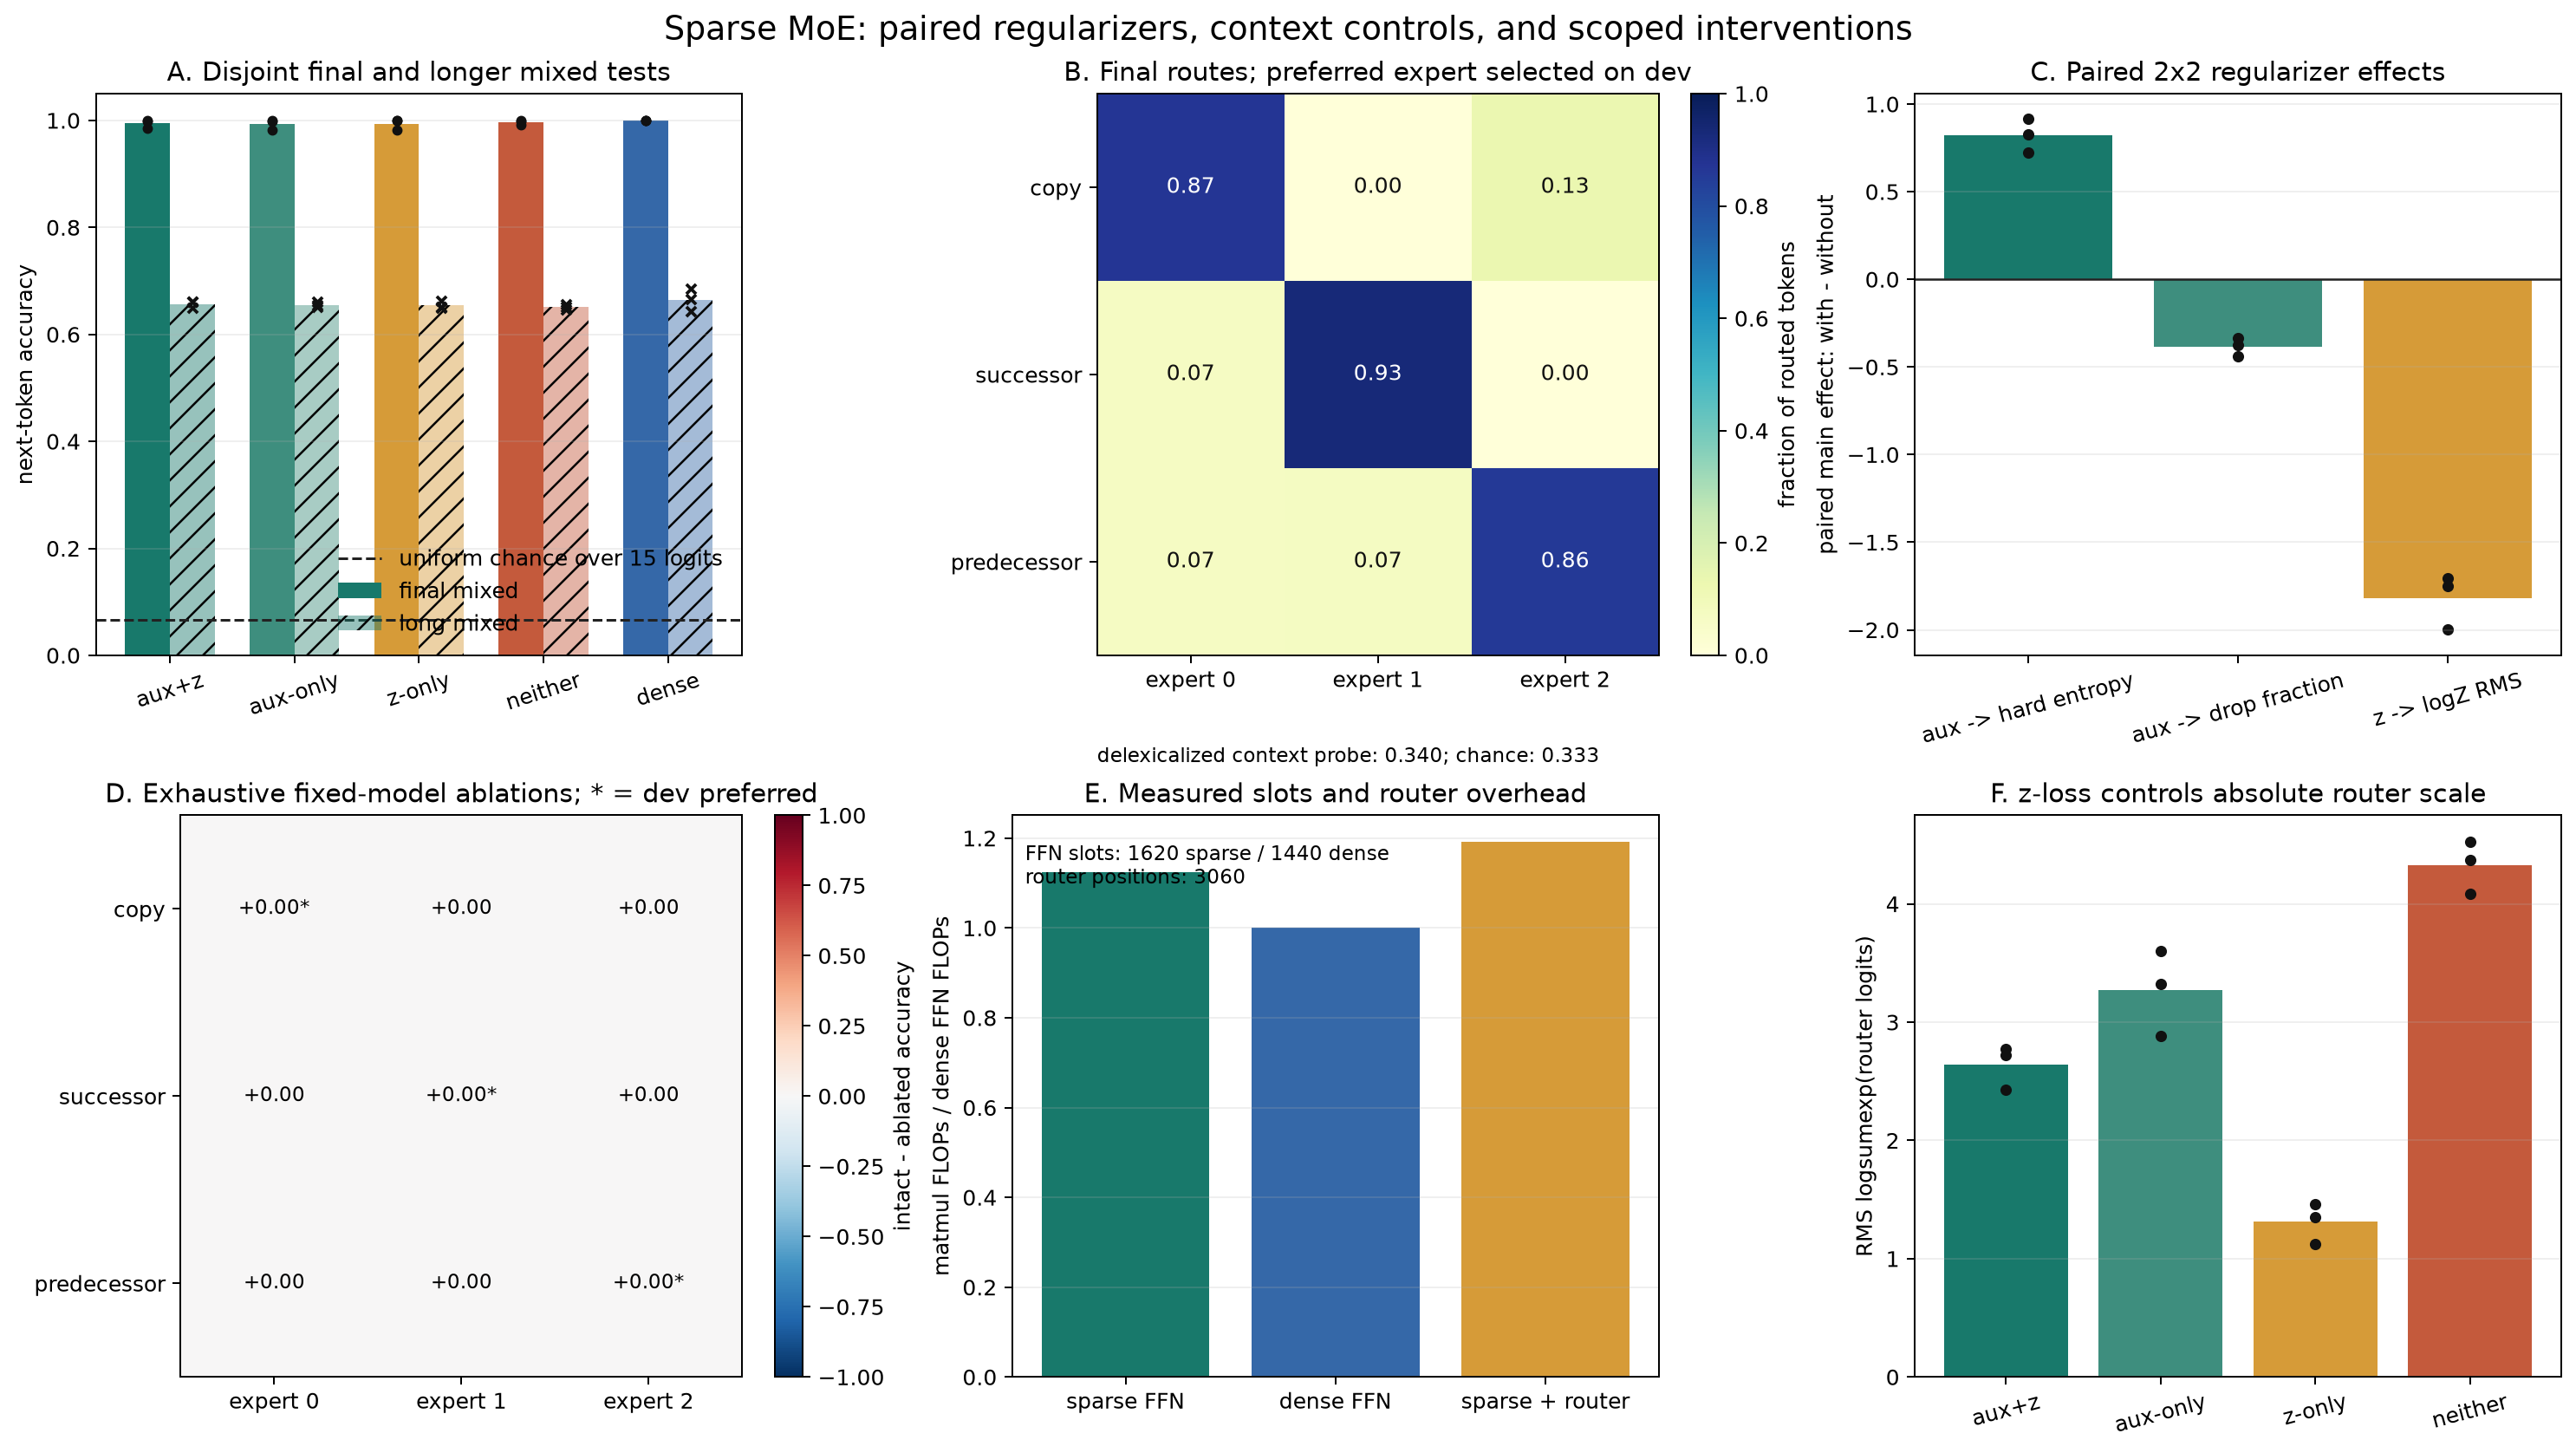

Preferred-expert ablation hypothesis: REJECTED
Original positive-specialization release contract: False
Mechanics and regularizer checks passed; inspect the specialization verdict above.


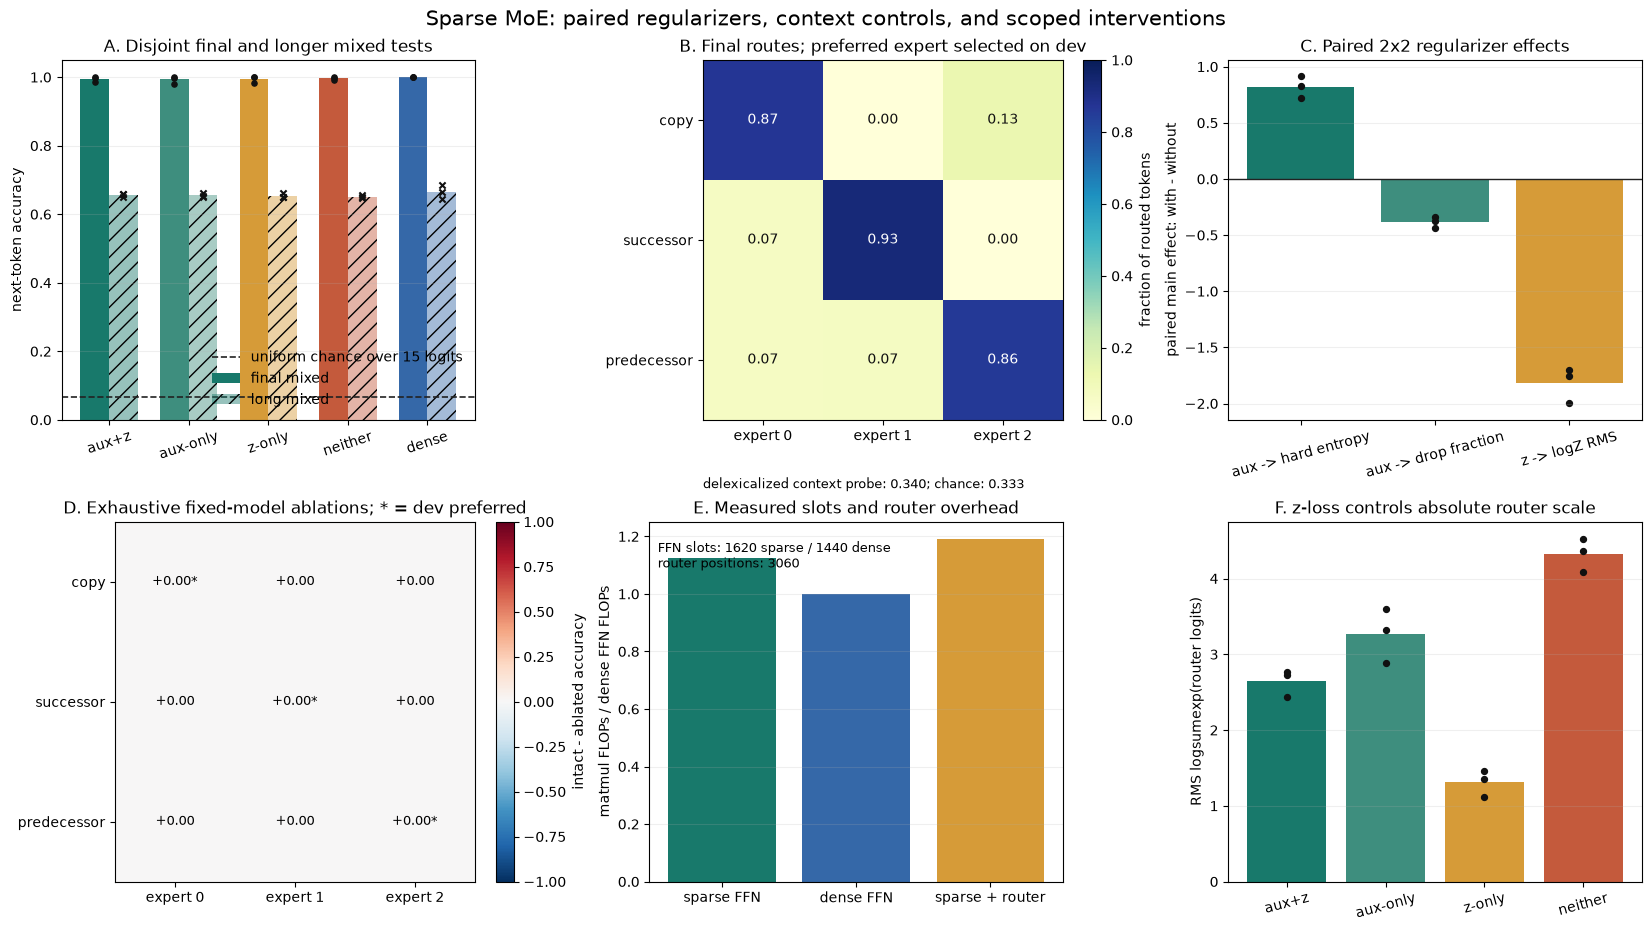

In [21]:
figure_path = root_dir / chapter / "instructions" / "assets" / "mixture_of_experts_signature.png"
signature_started = time.perf_counter()
signature = run_cpu_experiment(steps=180, seeds=(7, 19, 31), save_path=figure_path)
signature_seconds = time.perf_counter() - signature_started

headline_keys = (
    "aux_z_final_test_accuracy",
    "neither_final_test_accuracy",
    "aux_z_hard_load_entropy",
    "neither_hard_load_entropy",
    "neither_dropped_fraction",
    "context_only_router_probe_accuracy",
    "context_only_shuffled_label_probe_accuracy",
    "factorial_aux_main_effect_hard_load_entropy",
    "factorial_aux_main_effect_dropped_fraction",
    "factorial_z_main_effect_router_log_partition_rms",
    "preferred_expert_ablation_drop",
    "mean_nonpreferred_expert_ablation_drop",
    "preferred_expert_forcing_drop",
    "mean_nonpreferred_expert_forcing_drop",
    "router_evaluated_positions",
    "sparse_router_matmul_flops",
)
for name in headline_keys:
    print(f"{name:55s} mean={signature.metrics[name]:.6f} seeds={signature.seed_metrics[name]}")
print(f"CPU wall time: {signature_seconds:.3f}s")
print("dev routing by operation:\n", signature.dev_routing_by_regime)
print("dev-selected preferred experts:", signature.preferred_experts.tolist())
print("final routing by operation:\n", signature.routing_by_regime)
print("requested / kept counts:", signature.requested_counts.tolist(), signature.kept_counts.tolist())
print("intact accuracy:", signature.intervention.intact_accuracy.tolist())
print("all-expert ablated accuracy:\n", signature.intervention.ablated_accuracy)
print("all-expert forced accuracy:\n", signature.intervention.forced_accuracy)
display(Image(filename=str(figure_path)))

assert signature.metrics["aux_z_final_test_accuracy"] >= 0.98
assert signature.metrics["dense_equal_width_final_test_accuracy"] >= 0.98
assert signature.metrics["aux_z_long_mixed_accuracy"] >= 0.60
assert signature.metrics["aux_z_hard_load_entropy"] >= 0.95
assert signature.metrics["neither_hard_load_entropy"] <= 0.05
assert signature.metrics["neither_dropped_fraction"] >= 0.60
assert signature.metrics["context_only_router_probe_accuracy"] <= ROUTER_PROBE_CHANCE_ACCURACY + 0.12
assert signature.metrics["context_only_shuffled_label_probe_accuracy"] <= ROUTER_PROBE_CHANCE_ACCURACY + 0.12
assert signature.metrics["factorial_aux_main_effect_hard_load_entropy"] > 0.20
assert signature.metrics["factorial_aux_main_effect_dropped_fraction"] < -0.20
assert signature.metrics["factorial_z_main_effect_router_log_partition_rms"] < 0
specialization_supported = signature.metrics["preferred_expert_ablation_drop"] > signature.metrics["mean_nonpreferred_expert_ablation_drop"]
print("Preferred-expert ablation hypothesis:", "SUPPORTED" if specialization_supported else "REJECTED")
print("Original positive-specialization release contract:", _signature_result_is_accepted(signature))
assert signature.metrics["mean_nonpreferred_expert_forcing_drop"] > signature.metrics["preferred_expert_forcing_drop"]
assert signature.metrics["coherent_expert_permutation_max_diff"] <= 3e-6
assert signature.metrics["sparse_executed_ffn_slots"] == 1620, "Account for per-sequence capacity rounding."
assert signature.metrics["sparse_ffn_matmul_flops"] / signature.metrics["dense_ffn_matmul_flops"] == 1.125, "Padded sparse work exceeds this equal-width dense control."
assert signature.metrics["router_evaluated_positions"] > signature.metrics["active_operation_tokens"]
print("Mechanics and regularizer checks passed; inspect the specialization verdict above.")

## Interpreting the Result

- **Panel A:** all models are scored over the evaluator's full 15-logit prediction support, so uniform chance is `1/15`. The five data tokens are the only targets, but the evaluator does not suppress the other ten logits.
- **Panel B:** final hard routes are descriptive because the operation token legitimately enters the model. Stars use preferred experts selected on disjoint dev data. The separately reported delexicalized context probe stays near its three-class `1/3` chance.
- **Panel C:** each dot is one independently initialized/trained seed. Positive aux effects on hard-load entropy and negative aux effects on drop fraction directly test load balancing; a negative z effect on log-partition RMS directly tests scale control.
- **Panel D:** the first seed's fixed model is evaluated in every expert-by-operation ablation cell. No resampled choices are treated as repetitions.
- **Panel E:** sparse FFNs execute 12.5% more padded slots than the dense control on this stream. Router FLOPs use every routed input position, not only operation positions admitted to experts.
- **Panel F:** raw log-partition RMS by condition makes the z-loss scale effect visible alongside the paired contrast.

The preferred-expert ablation hypothesis is rejected on this run: the mean preferred drop is zero, while forcing nonpreferred experts is disruptive. These are different interventions. Preserved argmax accuracy does not prove zero logit effect, and forcing damage does not establish that a normally used expert is necessary. The long-stream accuracy near 0.66 is another visible limitation.

## Try It Yourself

Change `play_aux`, `play_z`, or `play_capacity`, then inspect the training trace, requested/kept expert counts, dev and final route tables, and every final intervention. This 60-step run is exploratory and is not used by signature acceptance checks.

In [22]:
play_seed = 43
play_aux = 0.2
play_z = 0.0
play_capacity = 0.75
play_training = TrainingConfig(steps=60, batch_size=63, train_data_tokens=9, eval_every=20, seed=play_seed)
play_streams = build_disjoint_mixed_streams(play_training, seed=play_seed, device=device)
play_models, _ = clone_factorial_models(MoEConfig(capacity_factor=play_capacity), seed=play_seed)
play_model = play_models["aux-only"]
play_trace = train_sparse_model(
    play_model,
    play_training,
    aux_coefficient=play_aux,
    z_coefficient=play_z,
    device=device,
    train_batches=play_streams.train_batches,
    dev_sequences=play_streams.dev_sequences,
)
play_accuracy, play_moe = evaluate_sparse(
    play_model,
    play_streams.final_test_sequences,
    capacity_factor=play_capacity,
)
play_inputs = play_streams.final_test_sequences[:, :-1]
play_mask = play_inputs.ge(REGIME_TOKEN_OFFSET) & play_inputs.lt(DATA_TOKEN_OFFSET)
play_dev_routing = routing_by_regime(play_model, play_streams.dev_sequences)
play_final_routing = routing_by_regime(play_model, play_streams.final_test_sequences)
play_preferred = play_dev_routing.argmax(dim=-1)
play_intervention = causal_expert_intervention_table(play_model, play_streams.final_test_sequences)
print("trace steps:", play_trace.steps)
print("trace hard-load entropy:", play_trace.hard_load_entropies)
print("trace drop fraction:", play_trace.dropped_fractions)
print("trace log-partition RMS:", play_trace.router_log_partition_rms)
print({
    "final_test_accuracy": play_accuracy,
    "soft_probability_entropy": normalized_router_entropy(play_moe.router.probabilities, play_mask),
    "hard_load_entropy": normalized_load_entropy(play_moe.capacity.requested_counts),
    "dropped_fraction": play_moe.capacity.dropped_fraction,
    "requested_counts": play_moe.capacity.requested_counts.tolist(),
    "kept_counts": play_moe.capacity.kept_counts.tolist(),
})
print("dev routing:\n", play_dev_routing)
print("dev-selected preferred experts:", play_preferred.tolist())
print("final routing:\n", play_final_routing)
print("all-expert ablated accuracy:\n", play_intervention.ablated_accuracy)
print("all-expert forced accuracy:\n", play_intervention.forced_accuracy)

trace steps: (1, 20, 40, 60)
trace hard-load entropy: (-0.0, -0.0, 0.6287331581115723, 0.8858570456504822)
trace drop fraction: (0.75, 0.75, 0.5027777777777778, 0.4361111111111111)
trace log-partition RMS: (3.8081777095794678, 3.160674571990967, 2.755934953689575, 2.6848597526550293)
{'final_test_accuracy': 0.4729166626930237, 'soft_probability_entropy': 0.9956994652748108, 'hard_load_entropy': 0.8677366971969604, 'dropped_fraction': 0.4361111111111111, 'requested_counts': [290, 290, 860], 'kept_counts': [244, 209, 359]}
dev routing:
 tensor([[0.6102, 0.1610, 0.2288],
        [0.0000, 0.0041, 0.9959],
        [0.0041, 0.4959, 0.5000]])
dev-selected preferred experts: [0, 2, 2]
final routing:
 tensor([[0.6042, 0.1937, 0.2021],
        [0.0000, 0.0042, 0.9958],
        [0.0000, 0.4012, 0.5988]])
all-expert ablated accuracy:
 tensor([[0.5083, 0.5042, 0.5063],
        [0.4198, 0.4198, 0.4198],
        [0.4712, 0.4712, 0.4691]])
all-expert forced accuracy:
 tensor([[0.3750, 0.4833, 0.3729],

## Limitations

- The task has five target values, three operations, one small decoder layer, and deliberately biased router initialization. It is a controlled model organism.
- The full-vocabulary uniform chance line is `1/15`; a classifier restricted to the five known target tokens would instead have `1/5` chance. This evaluator applies no such restriction.
- Current-token delexicalization removes direct operation-token identity but does not erase information in the causal prefix. Near-chance accuracy is therefore evidence about this generated stream, not a universal guarantee.
- The three seeds are genuine independent training repetitions, but three is still too few for population-level uncertainty claims. Expert identities are not aligned across seeds.
- Exhaustive interventions establish fixed-model dependence. They do not identify a unique mechanism when expert outputs can be redundant or compensatory.
- Padded expert buffers overstate optimized sparse-kernel work; accounting includes FFN and router matmuls, not GELU, bias, attention, communication, memory traffic, or wall-time parity.
- Finite capacity is allocated per forward call. Full-sequence and chunked decoding can retain different assignments; greedy cache tests use unbounded capacity.
- Switch top-1 uses its selected softmax probability; top-k with k greater than one uses a renormalized convention. The discrete selection is not differentiated.
- The complete learner path is CPU-only and uses no external checkpoint. CUDA is required only by strict parent release wrappers and is intentionally not exercised here.

## Further Research / Anomaly Hunting

- Increase `top_k` to 2 and compare Switch probability scaling with normalized multi-expert gates.
- Add independent seeds and align experts by behavior before aggregating route heatmaps.
- Replace padded expert loops with a segmented kernel and extend accounting to communication, memory traffic, and measured latency.
- Repeat the context-only assay on a stream with deliberately predictable operation schedules to see the control rise for a valid reason.

## Reading

- Shazeer et al., [Outrageously Large Neural Networks](https://arxiv.org/abs/1701.06538)
- Fedus et al., [Switch Transformers](https://arxiv.org/abs/2101.03961)
- Zoph et al., [ST-MoE](https://arxiv.org/abs/2202.08906)

## What You Established

You established exact routing and capacity semantics, direct aux/z interpretation tests, current-token-delexicalized probing, all-position router accounting, dev-selected exhaustive interventions, and repeated paired evidence from three independently trained models.